In [1]:
import numpy as np
import pandas as pd

_______________________

**EDA:**

_______________
بارگذاری داده

In [2]:
df = pd.read_csv('group_39_train.csv')

In [3]:
print("_"*30)
print("مرحله 1: بررسی اولیه")
print("_"*30)
print(f"ابعاد داده: {df.shape[0]} سطر و {df.shape[1]} ستون")
print("\nپنج سطر اول:")
print(df.head())
print("\nنام ستون‌ها:")
print(df.columns.tolist())
print("\nنوع داده هر ستون:")
print(df.dtypes)

______________________________
مرحله 1: بررسی اولیه
______________________________
ابعاد داده: 100000 سطر و 35 ستون

پنج سطر اول:
        f1                             f2                             f3  \
0  Source2            2019-12-16 06:43:34            2019-12-16 07:12:55   
1  Source2            2022-09-07 10:00:22            2022-09-07 10:29:34   
2  Source1  2020-09-15 13:41:30.000000000  2020-09-16 02:36:01.000000000   
3  Source1            2022-02-28 15:52:54            2022-02-28 18:03:24   
4  Source2            2018-01-17 17:04:34            2018-01-17 17:49:00   

          f4         f5         f6     f7                   f8           f9  \
0  40.845737 -73.931702        NaN  0.920               I-95 N     New York   
1  34.685730 -82.913040        NaN  0.000            Shiloh Rd       Seneca   
2  25.890186 -80.188322 -80.186124  0.146           NE 5th Ave  North Miami   
3  25.794325 -80.238373 -80.240302  0.120           NW 20th St        Miami   
4  38.631134 -90.2

_____________________________________
آمار توصیفی برای ویژگی‌های عددی



In [4]:
print("\n" + "_"*40)
print("مرحله 2: آمار توصیفی (ویژگی‌های عددی)")
print("_"*40)
# فقط ستون‌های عددی (int64, float64)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"ستون‌های عددی: {numeric_cols}")
print("\nآمار توصیفی:")
print(df[numeric_cols].describe())

# آمار توصیفی برای ستون هدف y (که عددی است)
if 'y' in numeric_cols:
    print("\nآمار توصیفی متغیر هدف y:")
    print(df['y'].value_counts().sort_index())
    print(f"\nدرصد هر مقدار در y:")
    print(df['y'].value_counts(normalize=True).sort_index() * 100)


________________________________________
مرحله 2: آمار توصیفی (ویژگی‌های عددی)
________________________________________
ستون‌های عددی: ['f4', 'f5', 'f6', 'f7', 'f16', 'f17', 'f18', 'f20', 'y']

آمار توصیفی:
                  f4             f5            f6             f7  \
count  100000.000000  100000.000000  56158.000000  100000.000000   
mean       36.230357     -94.695147    -95.761053       0.563887   
std         5.074071      17.430021     18.142290       1.725008   
min        24.571874    -124.512297   -124.509263       0.000000   
25%        33.423393    -117.234404   -117.794876       0.000000   
50%        35.863686     -87.707167    -88.034058       0.029000   
75%        40.106714     -80.349542    -80.244528       0.466000   
max        48.986034     -68.693464    -68.684626      74.370003   

                f16           f17           f18           f20              y  
count  74373.000000  98273.000000  97768.000000  92643.000000  100000.000000  
mean      58.279686  

____________________
بررسی مقادیر گمشده



In [5]:
print("\n" + "_"*50)
print("مرحله 3: بررسی مقادیر گمشده (Missing Values)")
print("_"*50)
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'count ': missing_counts, 'percentage': missing_percent})
missing_df = missing_df[missing_df['count '] > 0].sort_values(by='percentage', ascending=False)
if missing_df.empty:
    print("هیچ مقدار گمشده‌ای در داده وجود ندارد.")
else:
    print("ستون‌های دارای مقدار گمشده:")
    print(missing_df)


__________________________________________________
مرحله 3: بررسی مقادیر گمشده (Missing Values)
__________________________________________________
ستون‌های دارای مقدار گمشده:
     count   percentage
f6    43842      43.842
f16   25627      25.627
f20    7357       7.357
f18    2232       2.232
f19    2226       2.226
f21    2173       2.173
f17    1727       1.727
f15    1509       1.509
f14     299       0.299
f33     282       0.282
f34     282       0.282
f8      124       0.124
f13     102       0.102
f11      24       0.024
f9        3       0.003


In [6]:
# ذخیره خروجی در فایل
with open('EDA_Steps1_3_Output.txt', 'w', encoding='utf-8') as f:
    f.write("=== خروجی EDA مراحل 1 تا 3 ===\n")
    f.write(f"ابعاد: {df.shape}\n")
    f.write(f"ستون‌ها: {df.columns.tolist()}\n")
    f.write("\nتوزیع هدف y:\n")
    f.write(str(df['y'].value_counts().sort_index()) + "\n")
    f.write("\nمقادیر گمشده:\n")
    f.write(str(missing_df) + "\n")


________________________
تحلیل توزیع متغیر هدف

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# تنظیم ظاهر نمودارها
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

________________________________________
مرحله 4: توزیع متغیر هدف y
________________________________________


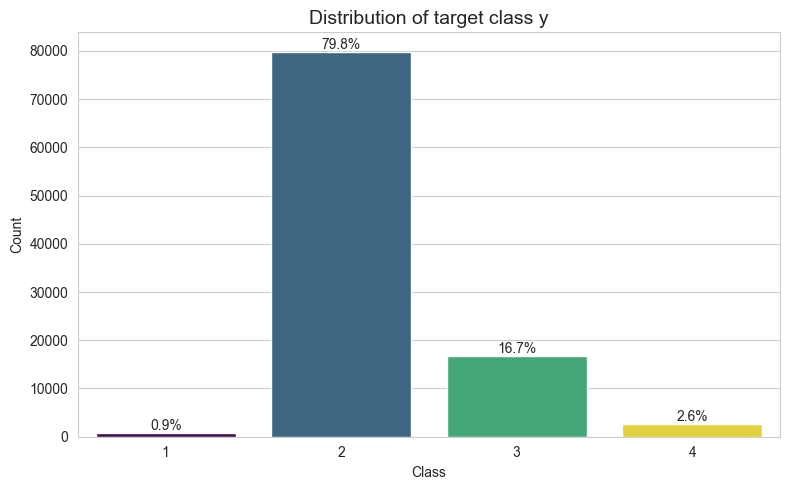

In [9]:
print("_"*40)
print("مرحله 4: توزیع متغیر هدف y")
print("_"*40)

plt.figure(figsize=(8,5))
ax = sns.countplot(x='y', data=df, hue='y', palette='viridis', legend=False)
plt.title('Distribution of target class y', fontsize=14)
plt.xlabel('Class')
plt.ylabel('Count')
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('y_distribution.png', dpi=150)
plt.show()


________________________
بررسی ویژگی های عددی مهم


________________________________________
مرحله 5: آنالیز ویژگی های عددی
________________________________________


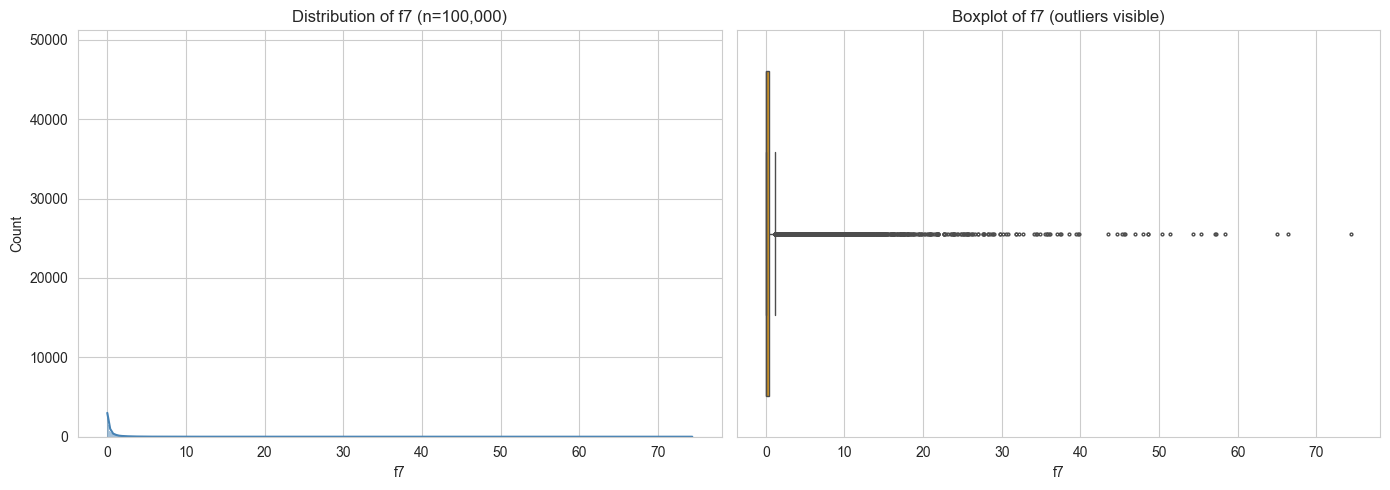

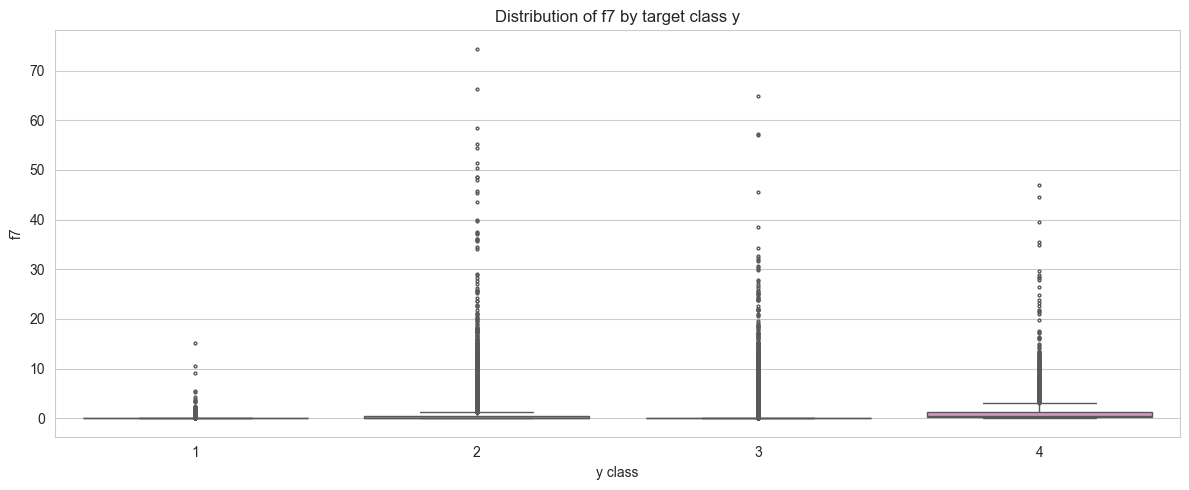

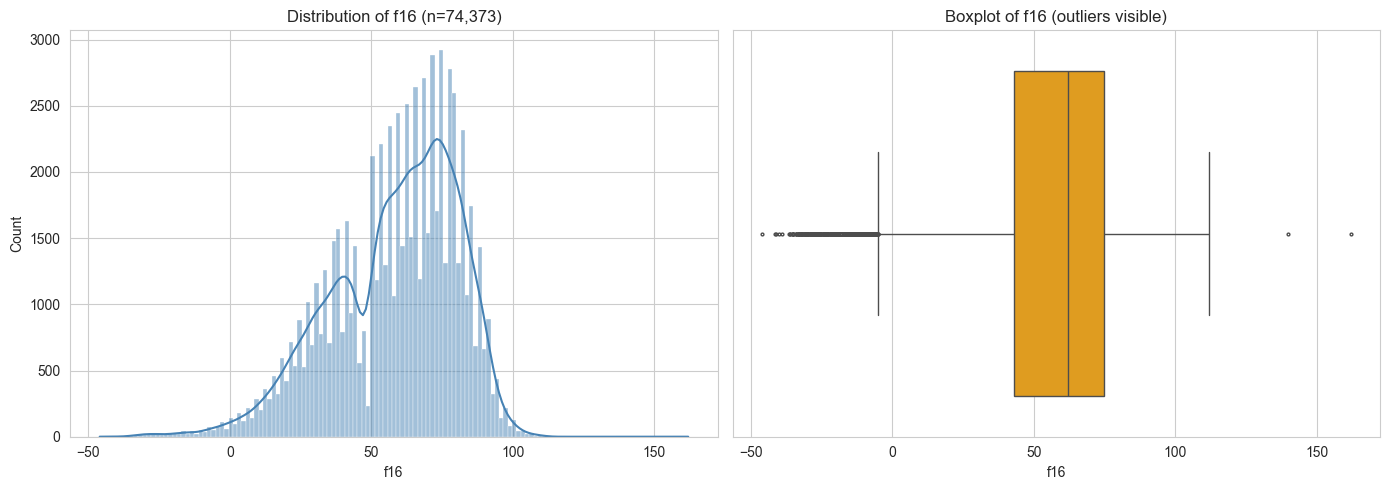

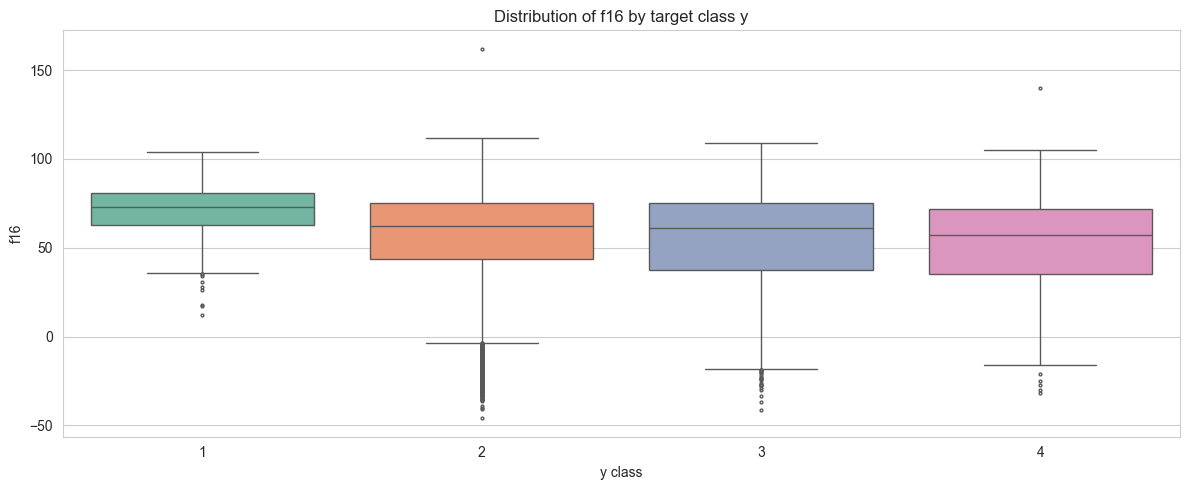

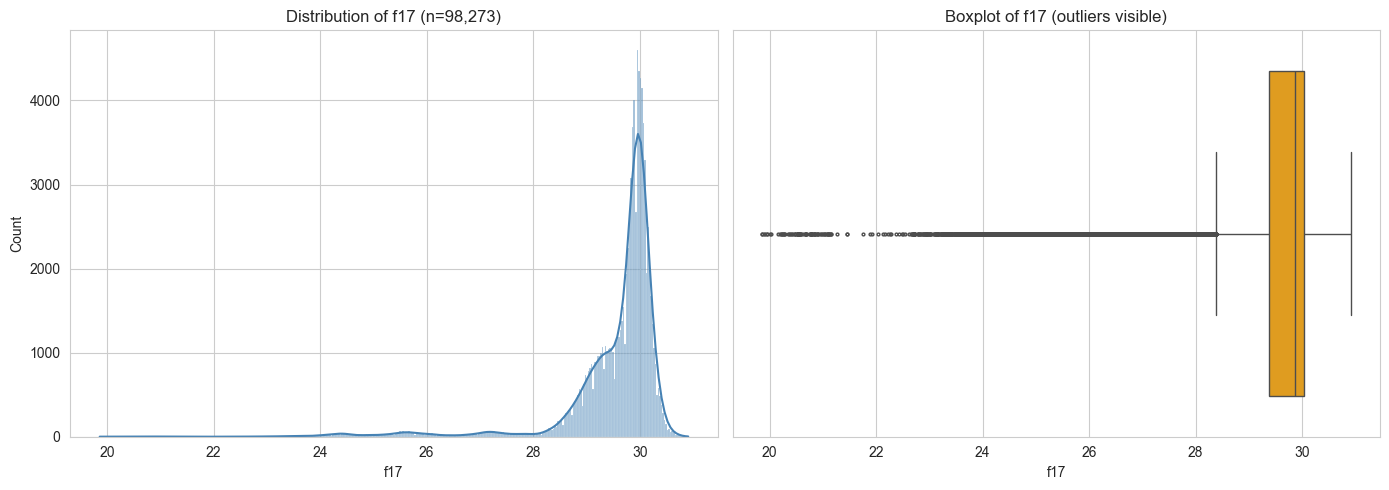

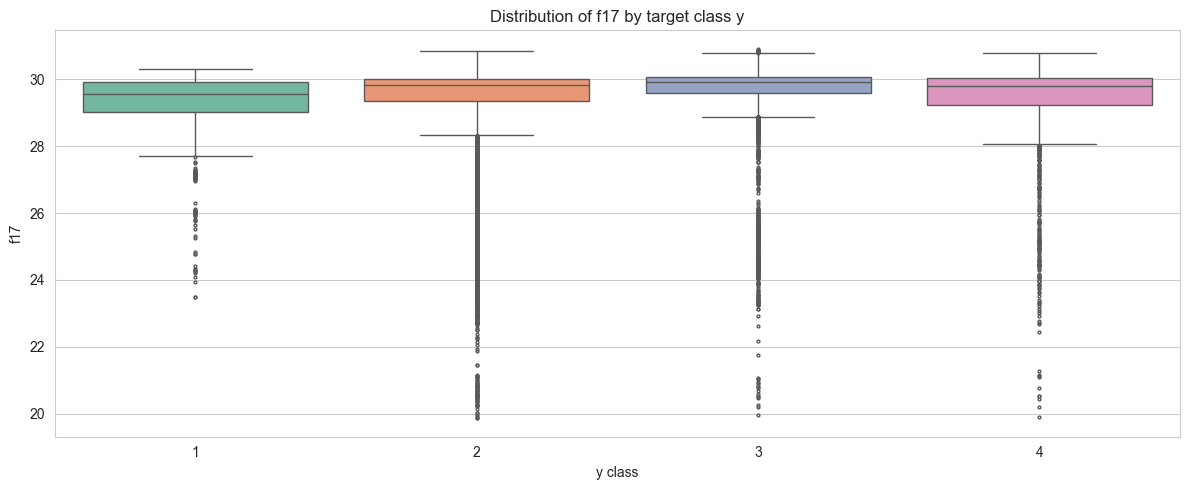

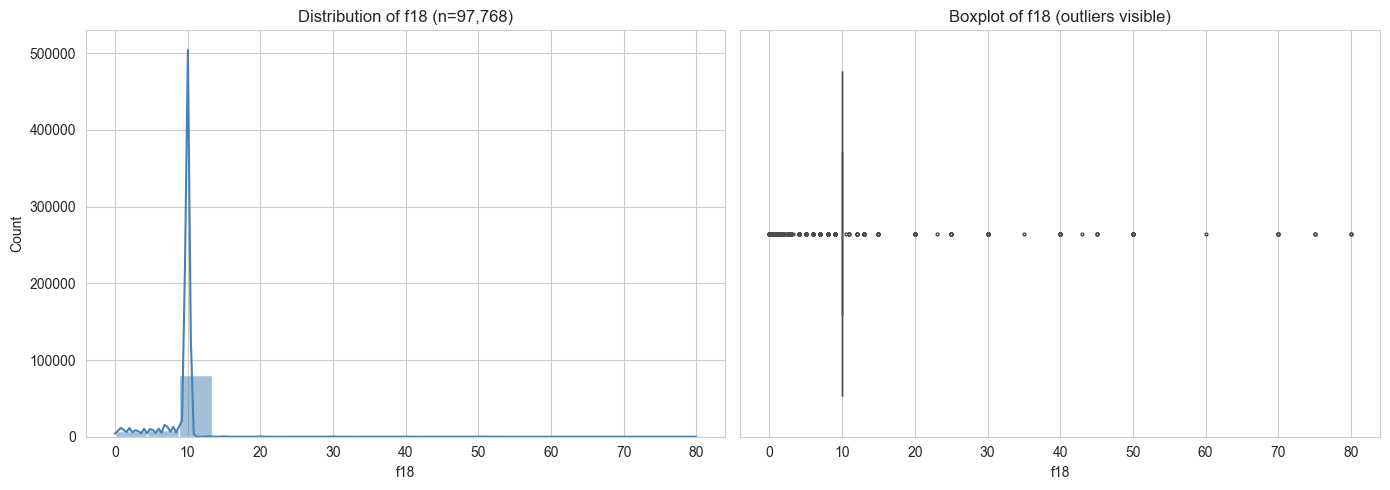

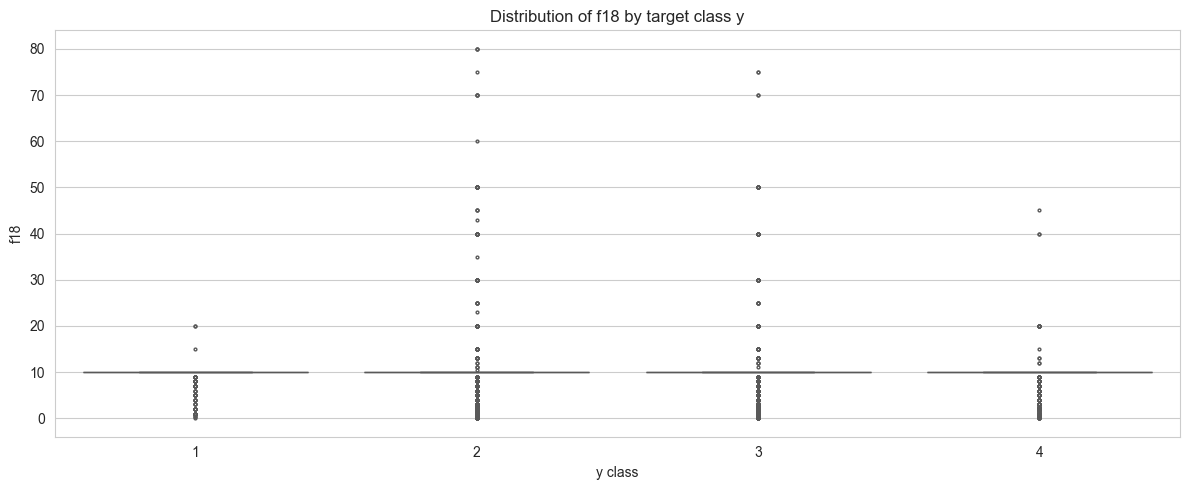

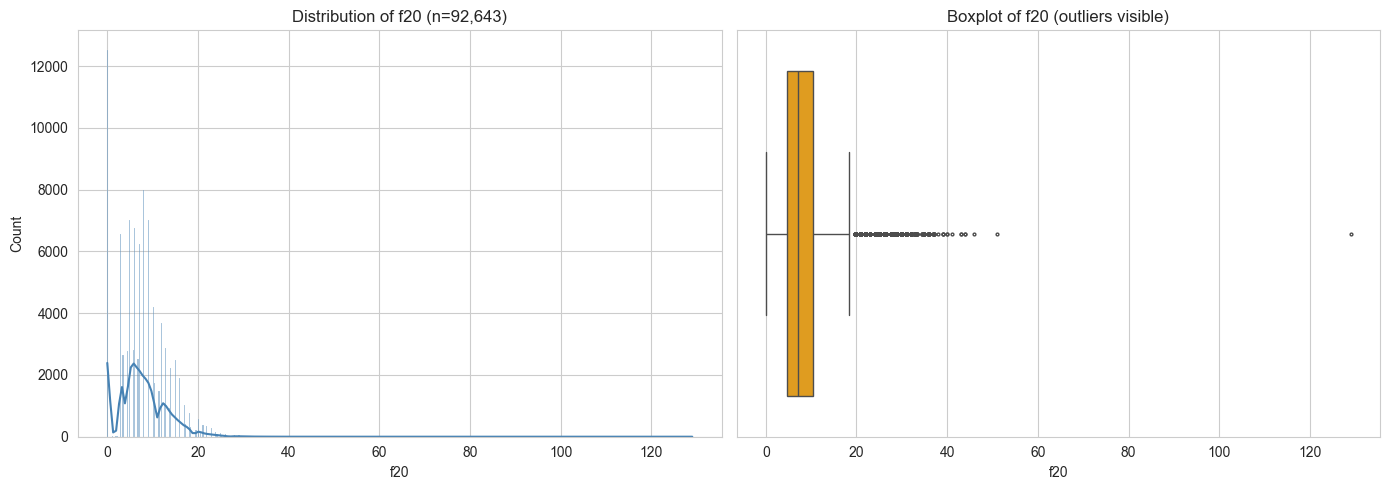

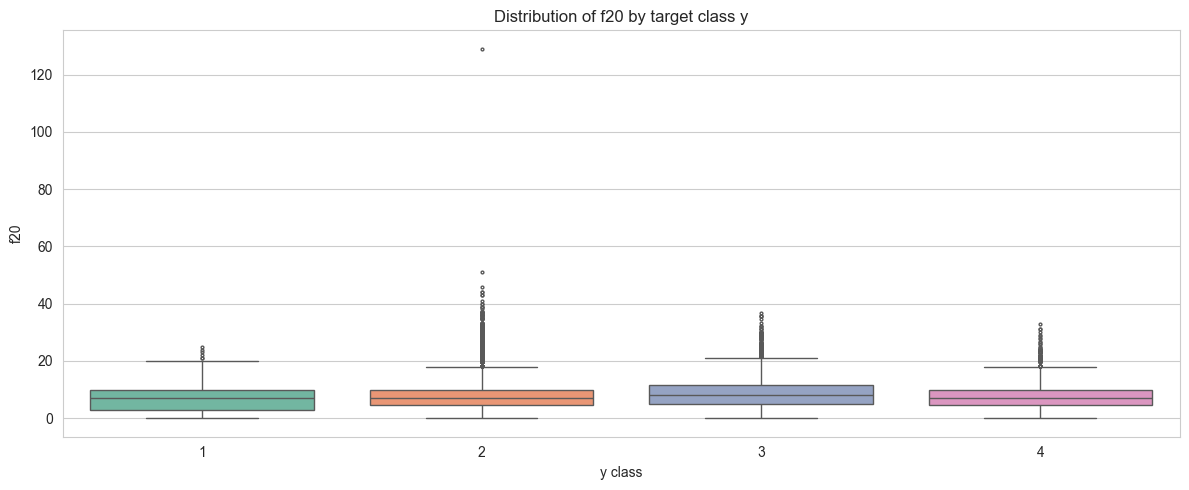

In [10]:
print("\n" + "_"*40)
print("مرحله 5: آنالیز ویژگی های عددی")
print("_"*40)

# لیست ویژگی‌های عددی: f7 (احتمالاً بارش/عمق آب) + دما، فشار، دید، سرعت باد
numerical_features = ['f7', 'f16', 'f17', 'f18', 'f20']

for col in numerical_features:
    if col in df.columns:
        data_col = df[col].dropna()
        if len(data_col) == 0:
            continue
            
        fig, axes = plt.subplots(1, 2, figsize=(14,5))
        
        # هیستوگرام
        sns.histplot(data_col, kde=True, ax=axes[0], color='steelblue')
        axes[0].set_title(f'Distribution of {col} (n={len(data_col):,})')
        axes[0].set_xlabel(col)
        
        # باکس‌پلات (outliers قابل مشاهده)
        sns.boxplot(x=data_col, ax=axes[1], color='orange', fliersize=2)
        axes[1].set_title(f'Boxplot of {col} (outliers visible)')
        axes[1].set_xlabel(col)
        
        plt.tight_layout()
        plt.savefig(f'{col}_distribution.png', dpi=150)
        plt.show()
        
        # مقایسه با y (باکس‌پلات تفکیک شده)
        temp_df = df[[col, 'y']].dropna()
        if len(temp_df) > 0:
            plt.figure(figsize=(12,5))
            sns.boxplot(x='y', y=col, data=temp_df, hue='y', palette='Set2', legend=False, fliersize=2)
            plt.title(f'Distribution of {col} by target class y')
            plt.xlabel('y class')
            plt.ylabel(col)
            plt.tight_layout()
            plt.savefig(f'{col}_by_y.png', dpi=150)
            plt.show()
        else:
            print(f"No data for {col} to compare with y.")


_____________________
شناسایی پرت‌ها با روش IQR


In [11]:
print("\n" + "_"*40)
print("مرحله 6:شناسایی داده های پرت")
print("_"*40)

outlier_cols = ['f7', 'f16', 'f20', 'f18']
outlier_report = []

for col in outlier_cols:
    if col not in df.columns:
        continue
    data = df[col].dropna()
    if len(data) == 0:
        continue
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data < lower) | (data > upper)]
    outlier_report.append({
        'feature': col,
        'count': len(outliers),
        'percent': 100 * len(outliers) / len(data),
        'lower_bound': lower,
        'upper_bound': upper,
        'min_val': data.min(),
        'max_val': data.max()
    })
    print(f"\n{col}:")
    print(f"  - Outliers count: {len(outliers)} ({100 * len(outliers) / len(data):.2f}%)")
    print(f"  - Normal range (IQR): [{lower:.2f}, {upper:.2f}]")
    print(f"  - Actual range: [{data.min():.2f}, {data.max():.2f}]")
    if col == 'f16' and data.max() > 120:
        print("  ⚠️ Extreme high temperature (>120°F) - consider capping or removal.")
    if col == 'f20' and data.max() > 100:
        print("  ⚠️ Extreme wind speed (>100 mph) - consider capping.")

if outlier_report:
    pd.DataFrame(outlier_report).to_csv('outlier_report.csv', index=False)
    print("\nOutlier report saved to 'outlier_report.csv'.")


________________________________________
مرحله 6:شناسایی داده های پرت
________________________________________

f7:
  - Outliers count: 12449 (12.45%)
  - Normal range (IQR): [-0.70, 1.17]
  - Actual range: [0.00, 74.37]

f16:
  - Outliers count: 571 (0.77%)
  - Normal range (IQR): [-5.00, 123.00]
  - Actual range: [-46.00, 162.00]
  ⚠️ Extreme high temperature (>120°F) - consider capping or removal.

f20:
  - Outliers count: 2683 (2.90%)
  - Normal range (IQR): [-4.10, 19.10]
  - Actual range: [0.00, 129.00]
  ⚠️ Extreme wind speed (>100 mph) - consider capping.

f18:
  - Outliers count: 19211 (19.65%)
  - Normal range (IQR): [10.00, 10.00]
  - Actual range: [0.00, 80.00]

Outlier report saved to 'outlier_report.csv'.


_________________________________
ماتریس همبستگی ویژگی‌های عددی


________________________________________
مرحله 7:ماتریس های همبستگی ویژگی های عددی
________________________________________


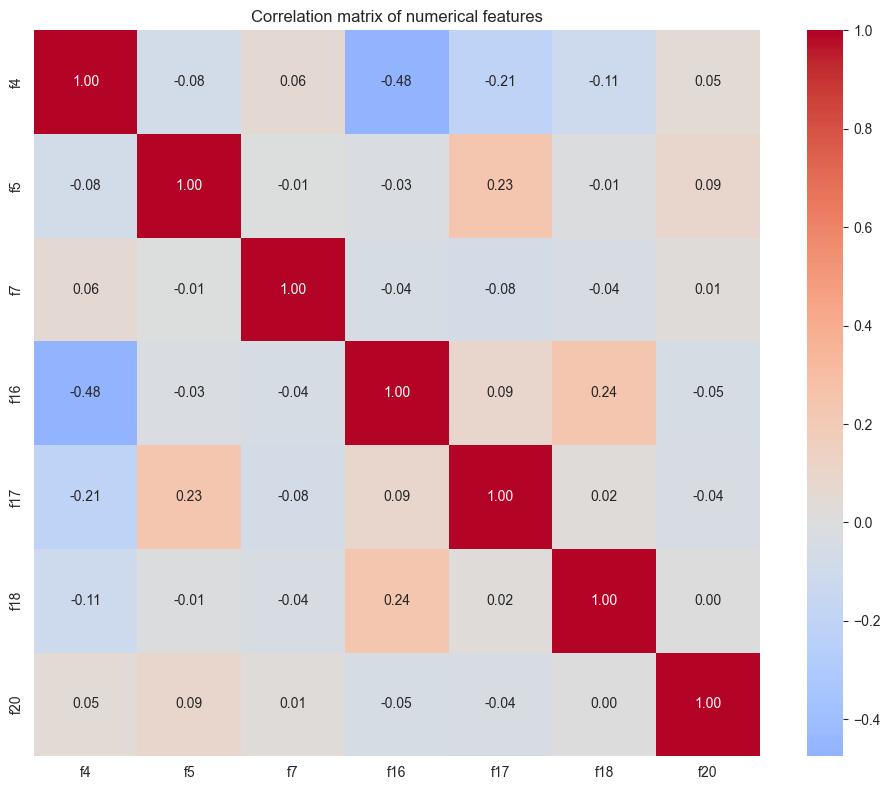


Correlation of numerical features with target y:
f4     0.083418
f5     0.079454
f7     0.038272
f20    0.030457
f17   -0.009662
f18   -0.011087
f16   -0.066724
dtype: float64


In [12]:
print("\n" + "_"*40)
print("مرحله 7:ماتریس های همبستگی ویژگی های عددی")
print("_"*40)

numerical_cols = ['f4', 'f5', 'f7', 'f16', 'f17', 'f18', 'f20']
numerical_cols = [c for c in numerical_cols if c in df.columns]

if len(numerical_cols) > 1:
    corr_df = df[numerical_cols].dropna()
    if len(corr_df) > 0:
        corr_matrix = corr_df.corr()
        plt.figure(figsize=(10,8))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
        plt.title('Correlation matrix of numerical features')
        plt.tight_layout()
        plt.savefig('corr_numerical.png', dpi=150)
        plt.show()
        
        y_temp = df.loc[corr_df.index, 'y']
        corr_with_y = corr_df.corrwith(y_temp).sort_values(ascending=False)
        print("\nCorrelation of numerical features with target y:")
        print(corr_with_y)
    else:
        print("Not enough data after dropping missing for correlation.")
else:
    print("Less than 2 numerical columns available.")

 ___________________
 بررسی ویژگی‌های دسته‌ای (categorical) و بولی



____________________________________________________________
مرحله 8:بررسی ویژگی های boolian و categorical
____________________________________________________________


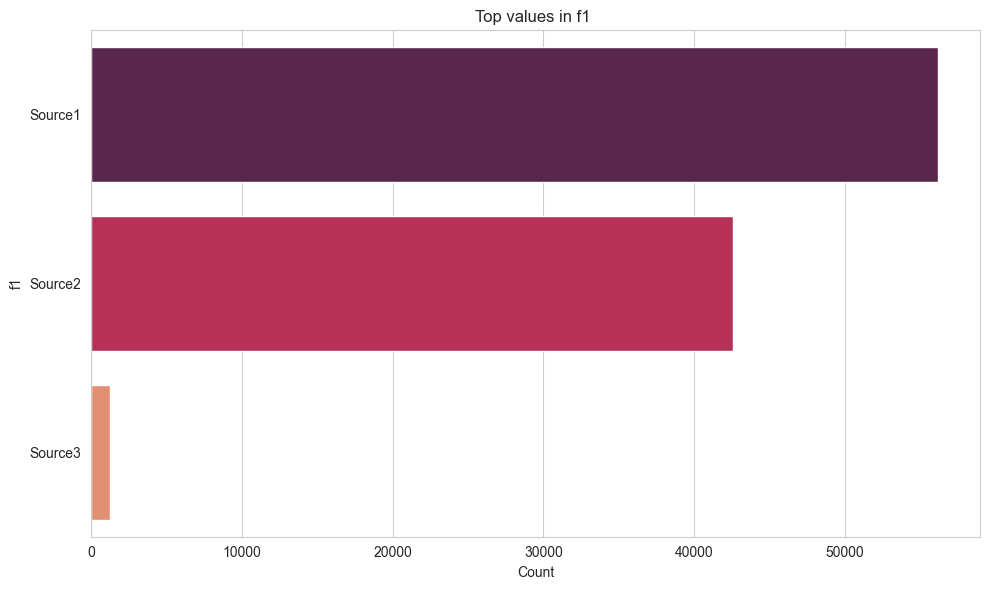


Relation of f1 with y (row %):
y               1          2          3         4
f1                                               
Source1  0.633926  91.415293   3.757256  4.193525
Source2  1.053941  65.086146  33.402188  0.457725
Source3  3.870968  63.306452  32.338710  0.483871


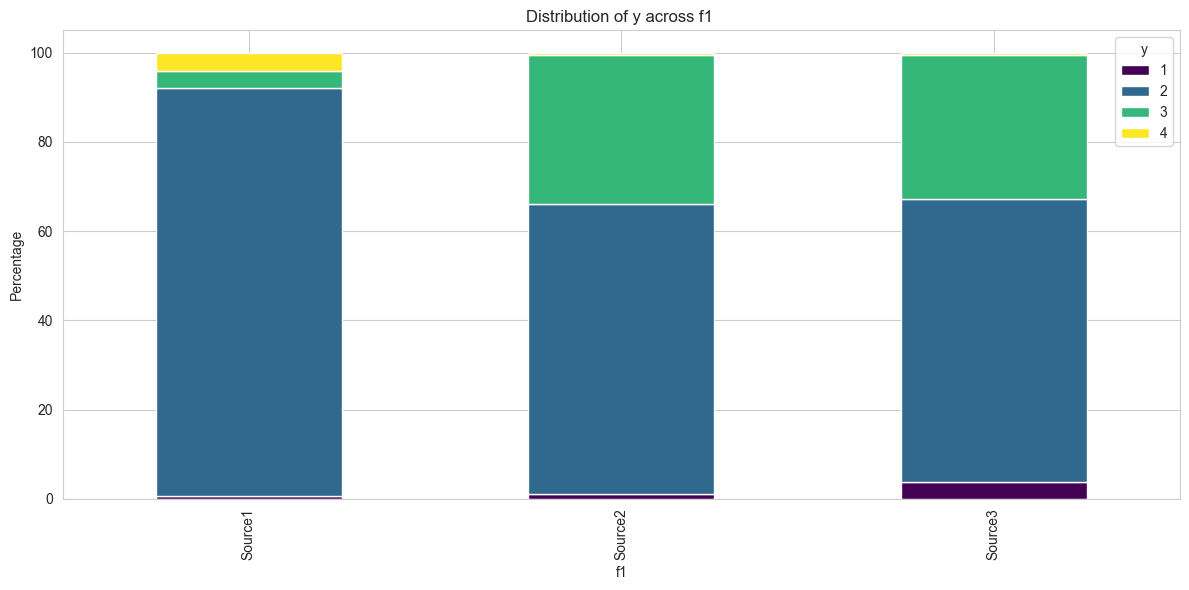

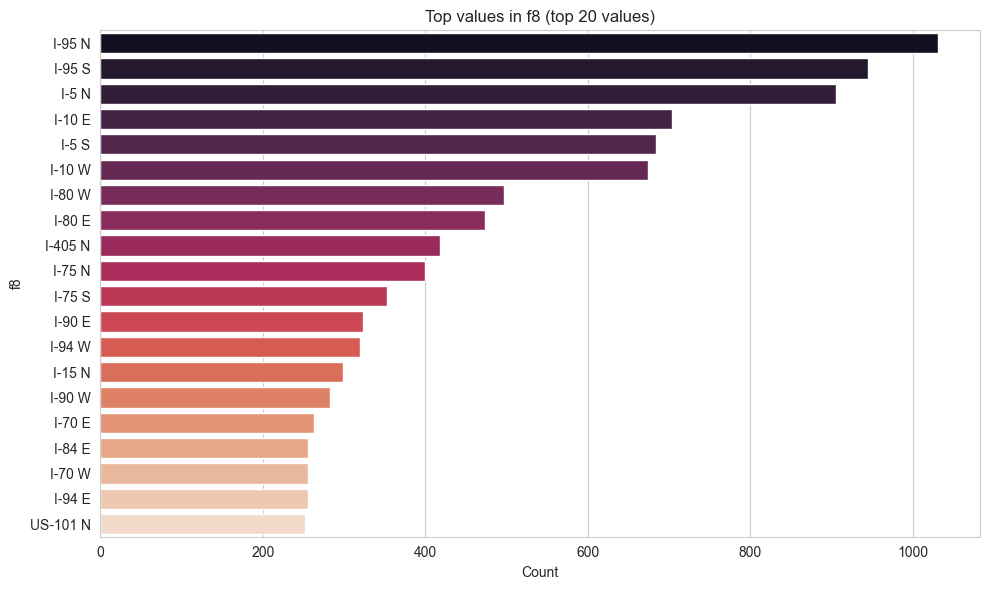


Relation of f8 with y (row %, top 20 values):
y               1          2          3         4
f8                                               
I-10 E   0.000000  62.162162  36.273115  1.564723
I-10 W   0.000000  60.979228  37.685460  1.335312
I-15 N   0.000000  61.872910  38.127090  0.000000
I-405 N  0.000000  56.698565  42.822967  0.478469
I-5 N    0.110497  66.298343  32.265193  1.325967
I-5 S    0.146199  73.830409  25.000000  1.023392
I-70 E   0.000000  57.794677  36.501901  5.703422
I-70 W   1.176471  54.901961  36.470588  7.450980
I-75 N   0.250000  49.000000  47.000000  3.750000
I-75 S   0.283286  52.407932  43.626062  3.682720


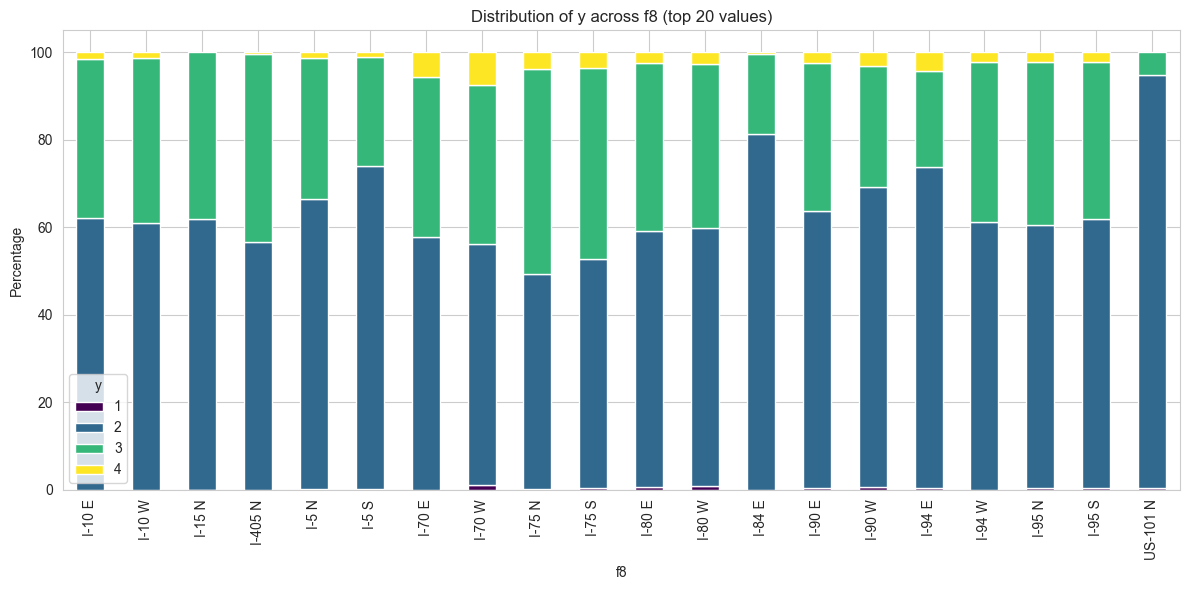

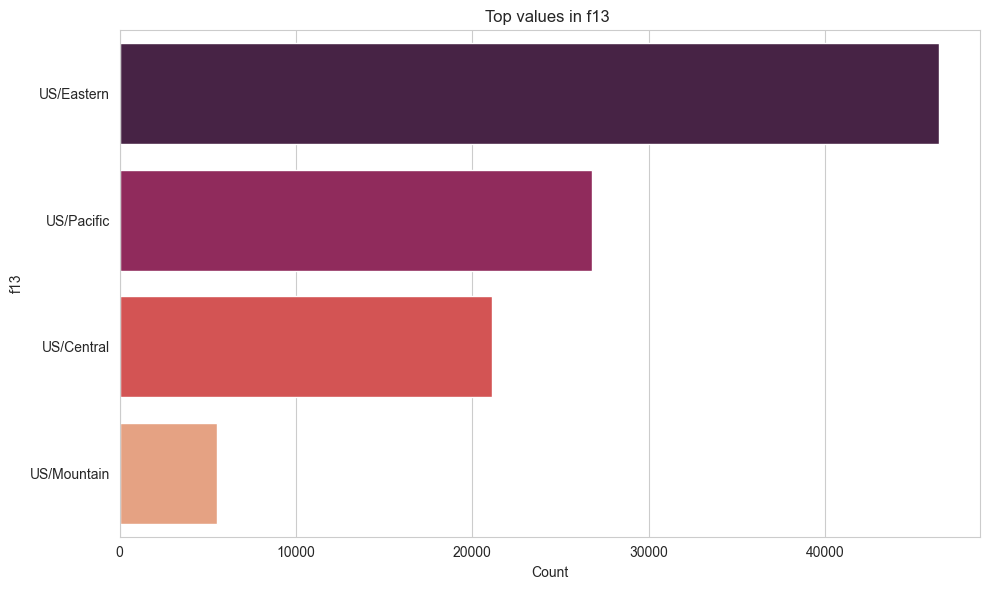


Relation of f13 with y (row %):
y                   1          2          3         4
f13                                                  
US/Central   0.672540  77.086293  20.233021  2.008146
US/Eastern   0.878099  79.252755  16.345988  3.523158
US/Mountain  2.031562  79.938328  14.474878  3.555233
US/Pacific   0.697579  83.019361  15.175141  1.107920


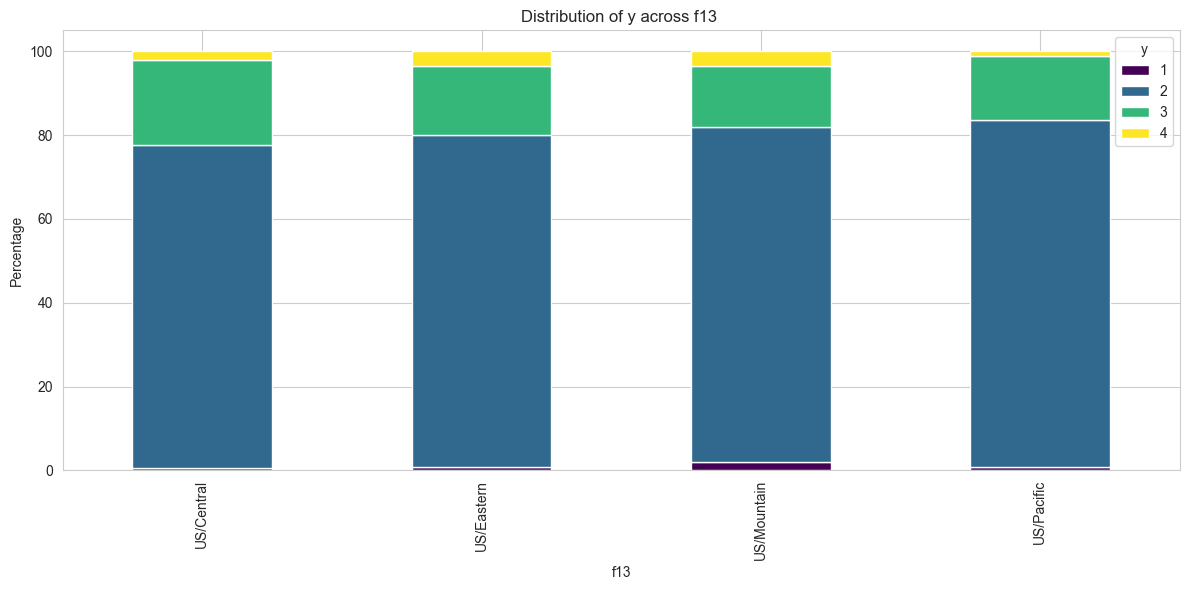

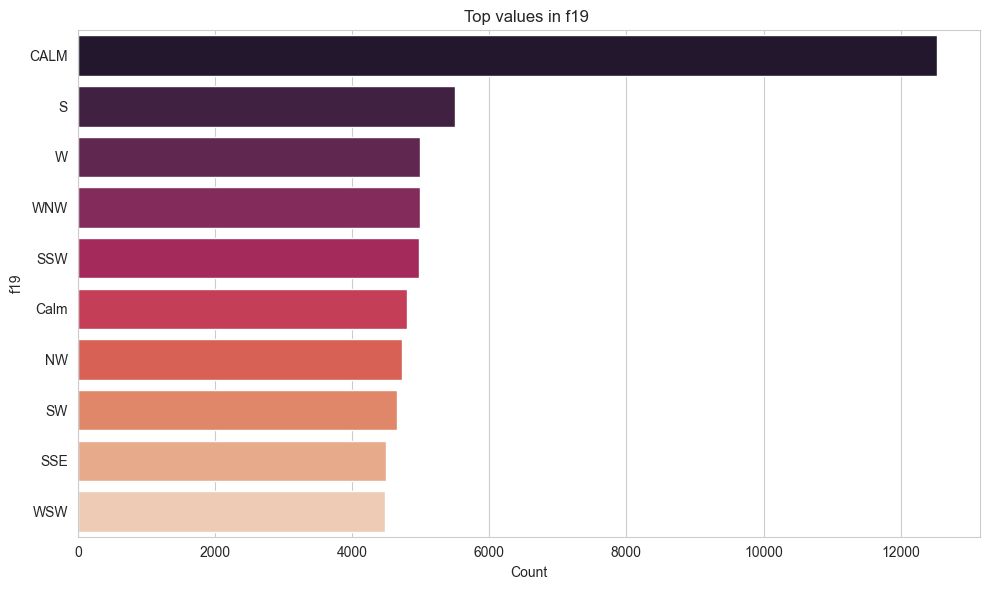


Relation of f19 with y (row %):
y            1          2          3         4
f19                                           
CALM  1.005667  87.309442   8.971187  2.713704
Calm  0.062539  64.957265  31.749010  3.231186
E     1.199442  86.248257  10.432357  2.119944
ENE   0.757576  80.448718  16.346154  2.447552
ESE   0.626424  79.897494  17.568337  1.907745
East  0.000000  64.784547  31.797920  3.417533
N     1.169293  86.553127   9.989832  2.287748
NE    1.117825  79.577039  16.374622  2.930514
NNE   1.004872  80.663825  16.352010  1.979294
NNW   0.754976  80.073210  16.449325  2.722489


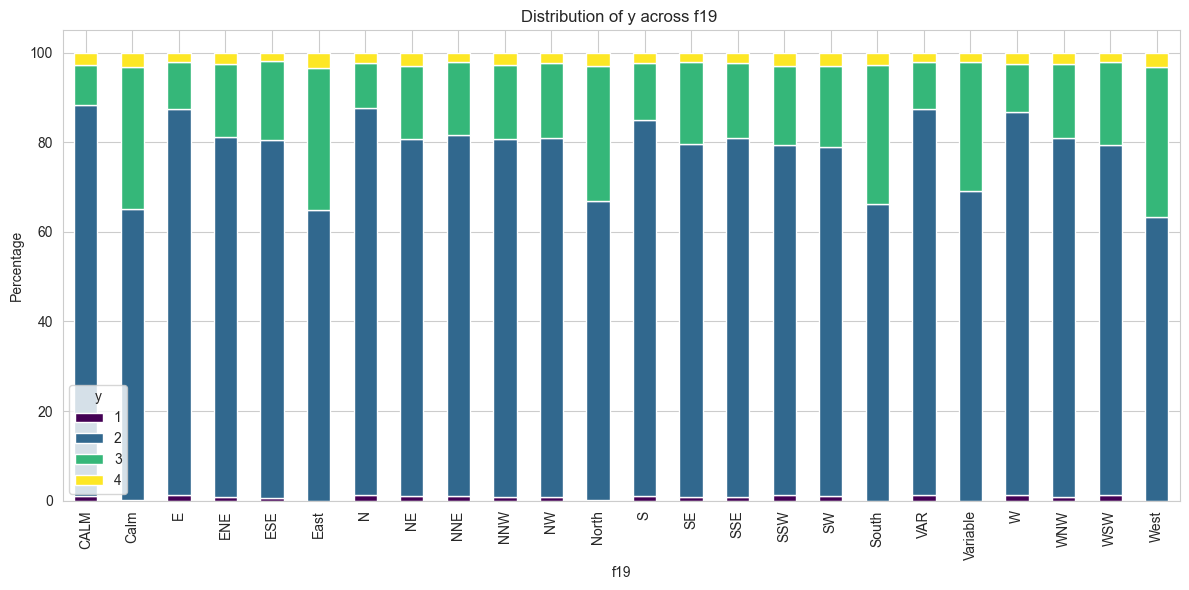

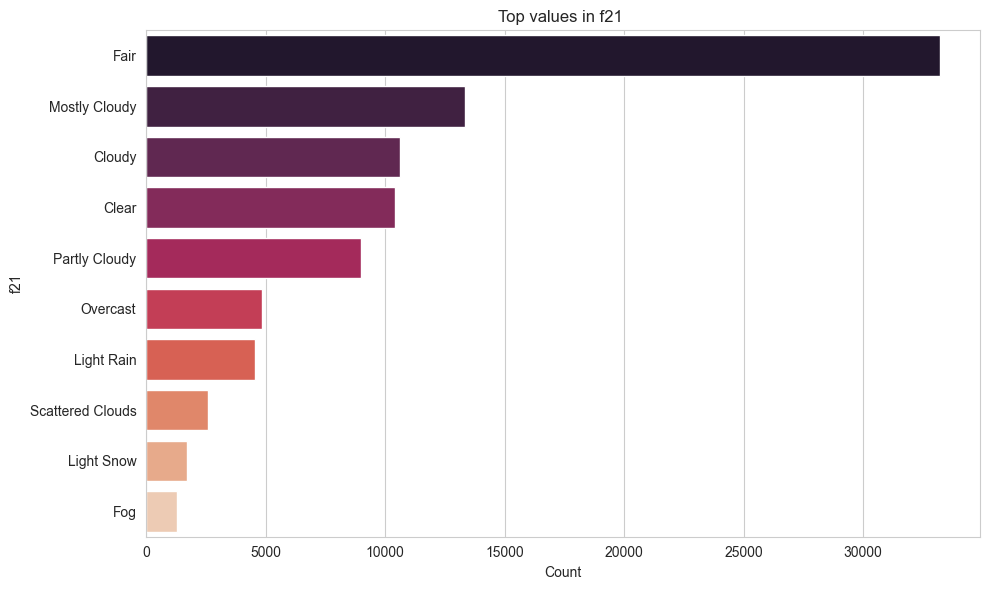


Relation of f21 with y (row %):
y                             1           2          3         4
f21                                                             
Blowing Snow           0.000000  100.000000   0.000000  0.000000
Blowing Snow / Windy   0.000000  100.000000   0.000000  0.000000
Clear                  0.057715   66.717968  30.126972  3.097345
Cloudy                 1.054912   84.797966  11.349722  2.797400
Cloudy / Windy         0.460829   85.253456  12.442396  1.843318
Drifting Snow / Windy  0.000000  100.000000   0.000000  0.000000
Drizzle                0.000000   73.015873  22.222222  4.761905
Drizzle and Fog        0.000000   66.666667  33.333333  0.000000
Fair                   1.218742   87.186663   9.340676  2.253920
Fair / Windy           0.871460   86.274510   9.368192  3.485839


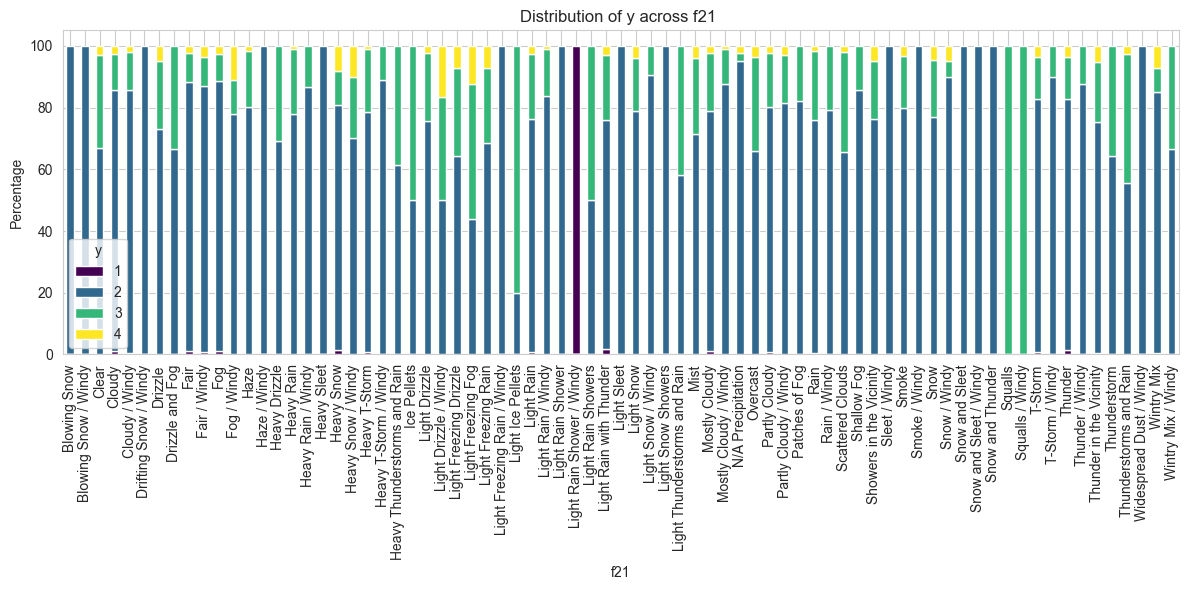

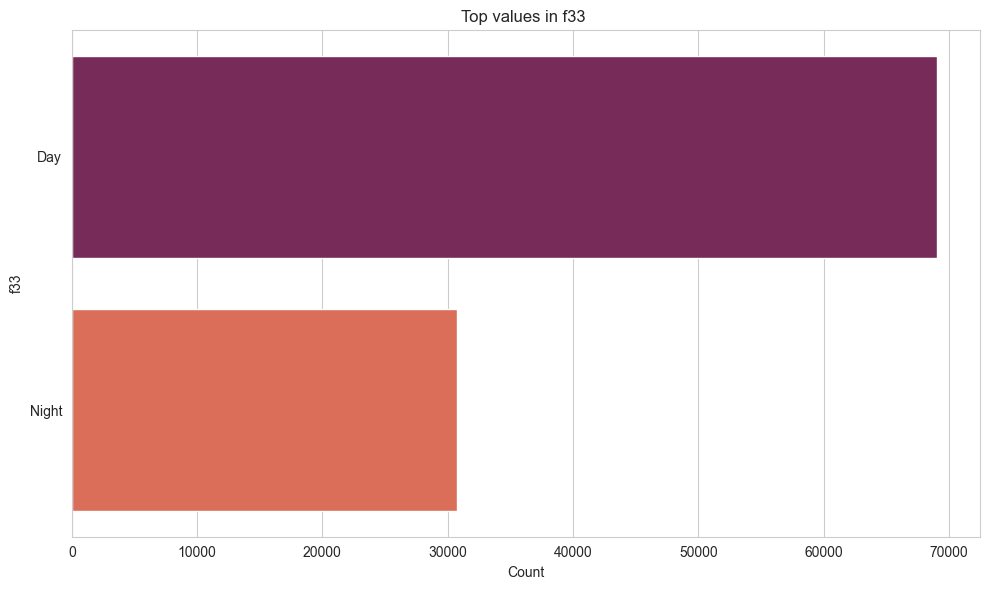


Relation of f33 with y (row %):
y             1          2          3         4
f33                                            
Day    1.001217  79.352614  17.481454  2.164715
Night  0.524396  80.910038  15.204221  3.361345


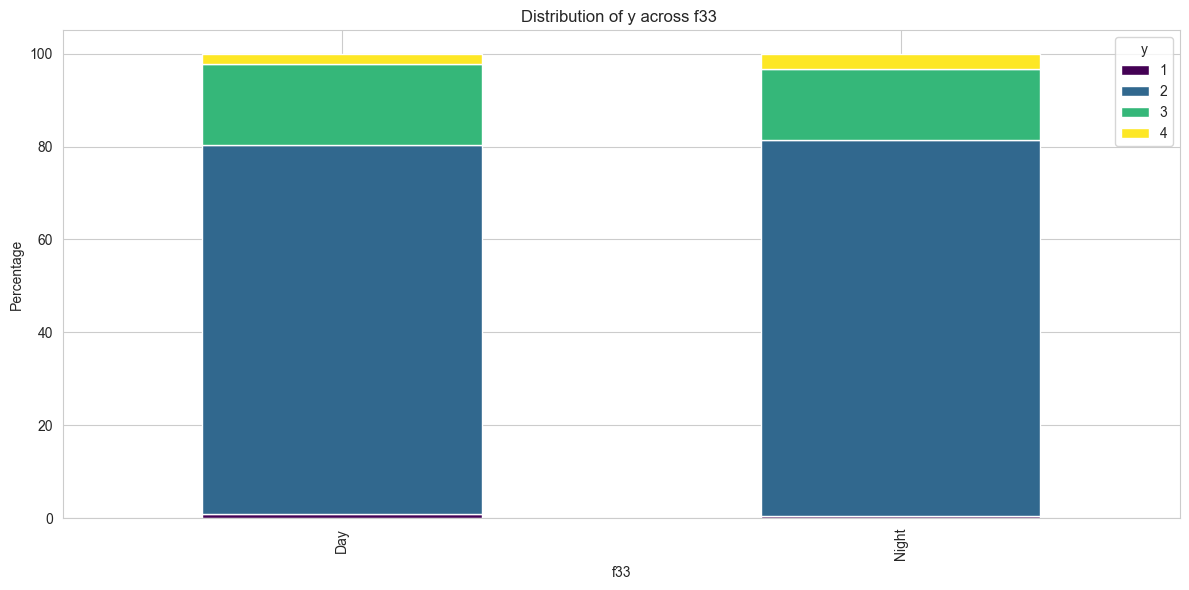

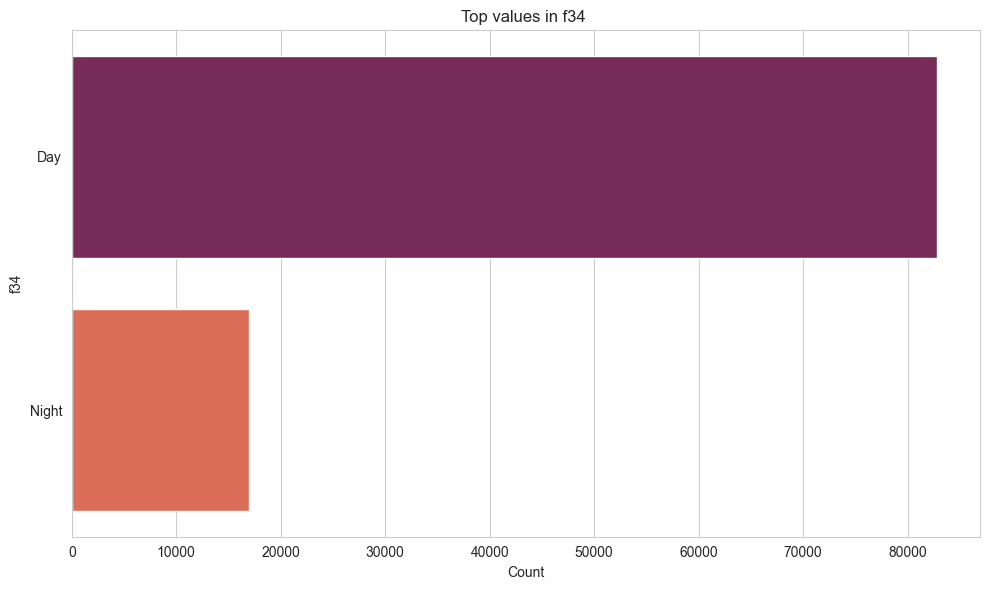


Relation of f34 with y (row %):
y             1          2          3         4
f34                                            
Day    0.944604  79.428889  17.415988  2.210519
Night  0.413418  81.803685  13.672336  4.110560


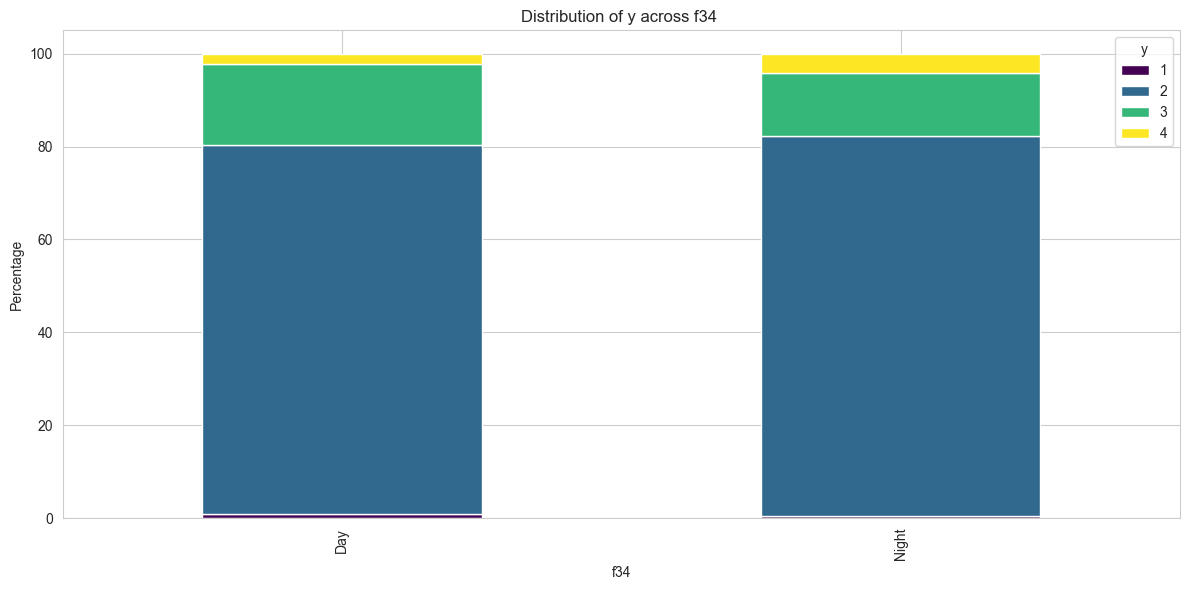

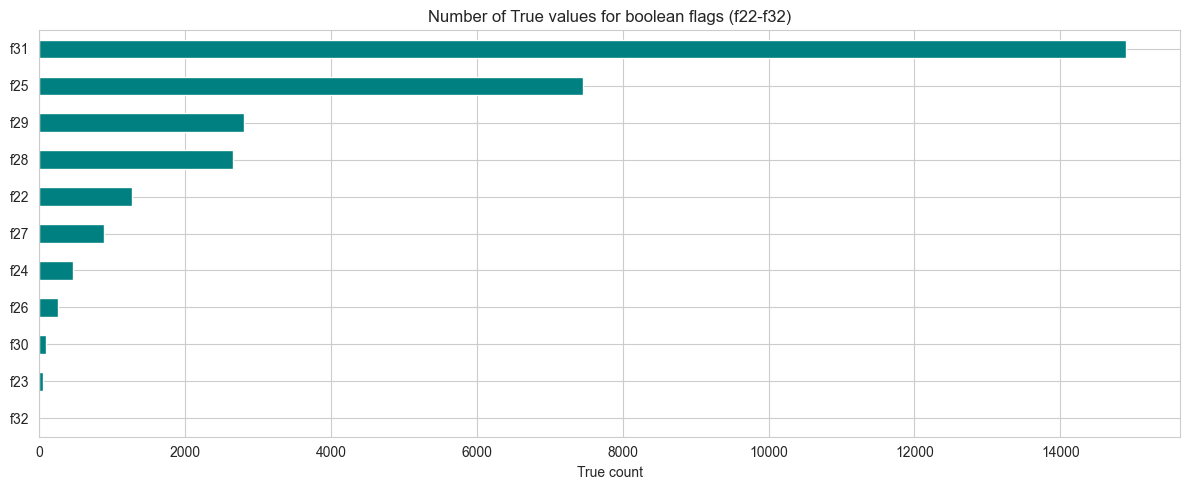

c:\Users\COMPCENTER\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\COMPCENTER\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


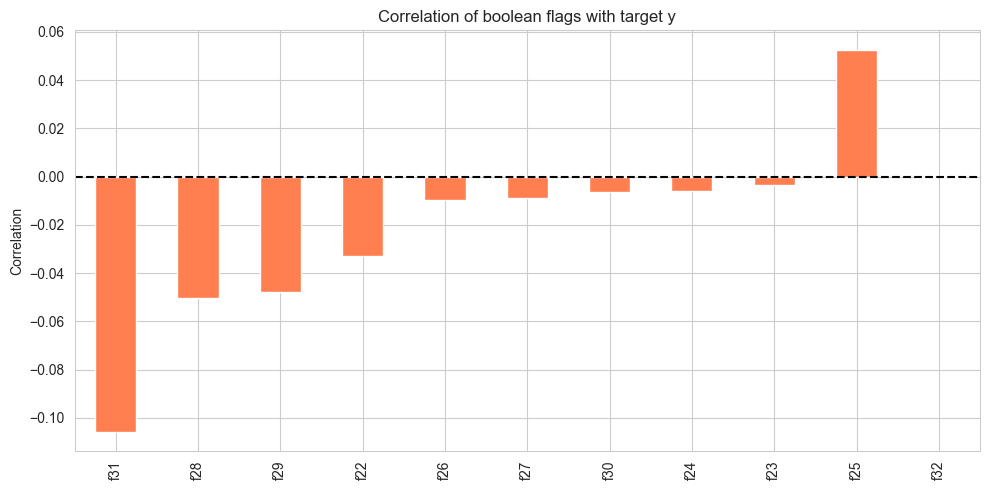

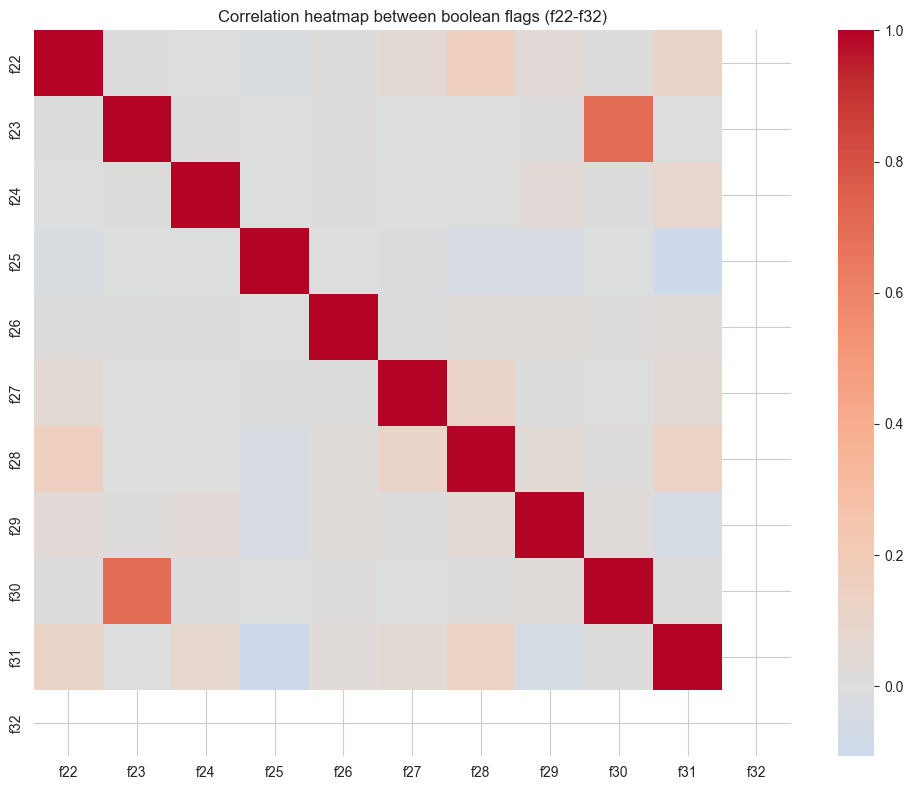

In [13]:
print("\n" + "_"*60)
print("مرحله 8:بررسی ویژگی های boolian و categorical")
print("_"*60)

# 6.1 ویژگی‌های دسته‌ای (categorical) - برای f8 از top-N استفاده می‌کنیم
categorical_cols = ['f1', 'f8','f13','f19', 'f21', 'f33', 'f34']

for col in categorical_cols:
    if col not in df.columns:
        continue
    
    # اگر ستون f8 باشد، فقط ۲۰ مقدار پرتکرار را بررسی کن
    if col == 'f8':
        # محاسبه فراوانی و انتخاب top 20
        top_vals = df[col].value_counts().head(20).index
        temp_df = df[df[col].isin(top_vals)].copy()
        if temp_df.empty:
            continue
        counts = temp_df[col].value_counts()
        title_suffix = "(top 20 values)"
    else:
        temp_df = df
        counts = df[col].value_counts().head(10)  # برای بقیه ۱۰ مقدار اول کافی است
        title_suffix = ""
    
    # نمودار میله‌ای افقی
    plt.figure(figsize=(10,6))
    sns.barplot(x=counts.values, y=counts.index, hue=counts.index, palette='rocket', legend=False)
    plt.title(f'Top values in {col} {title_suffix}')
    plt.xlabel('Count')
    plt.tight_layout()
    plt.savefig(f'{col}_top10.png', dpi=150)
    plt.show()
    
    # بررسی ارتباط با y (درصد ردیفی)
    # برای f8 فقط داده‌های top 20 را در نظر بگیر
    if col == 'f8':
        cross = pd.crosstab(temp_df[col], temp_df['y'], normalize='index') * 100
        print(f"\nRelation of {col} with y (row %, top 20 values):")
    else:
        cross = pd.crosstab(df[col], df['y'], normalize='index') * 100
        print(f"\nRelation of {col} with y (row %):")
    print(cross.head(10))
    
    # نمودار stacked bar
    cross.plot(kind='bar', stacked=True, figsize=(12,6), colormap='viridis')
    plt.title(f'Distribution of y across {col} {title_suffix}')
    plt.ylabel('Percentage')
    plt.xlabel(col)
    plt.legend(title='y')
    plt.tight_layout()
    plt.savefig(f'{col}_y_relation.png', dpi=150)
    plt.show()

# 6.2 ویژگی‌های بولی (f22 تا f32)
bool_cols = [f'f{i}' for i in range(22, 33)]  # f22 تا f32 inclusive
bool_data = df[bool_cols].copy()

# تعداد True برای هر flag
true_counts = bool_data.sum()
plt.figure(figsize=(12,5))
true_counts.sort_values().plot(kind='barh', color='teal')
plt.title('Number of True values for boolean flags (f22-f32)')
plt.xlabel('True count')
plt.tight_layout()
plt.savefig('bool_flags_true_counts.png', dpi=150)
plt.show()

# همبستگی بین flags و y
bool_int = bool_data.astype(int)
corr_with_y = bool_int.corrwith(df['y']).sort_values()
plt.figure(figsize=(10,5))
corr_with_y.plot(kind='bar', color='coral')
plt.title('Correlation of boolean flags with target y')
plt.axhline(y=0, color='black', linestyle='--')
plt.ylabel('Correlation')
plt.tight_layout()
plt.savefig('bool_corr_with_y.png', dpi=150)
plt.show()

# Heatmap همبستگی بین flags
plt.figure(figsize=(10,8))
sns.heatmap(bool_int.corr(), annot=False, cmap='coolwarm', center=0)
plt.title('Correlation heatmap between boolean flags (f22-f32)')
plt.tight_layout()
plt.savefig('bool_corr_heatmap.png', dpi=150)
plt.show()

______________
تحلیل ویژگی‌های جغرافیایی 


Geographical analysis: f4 (lat) vs f5 (lon)


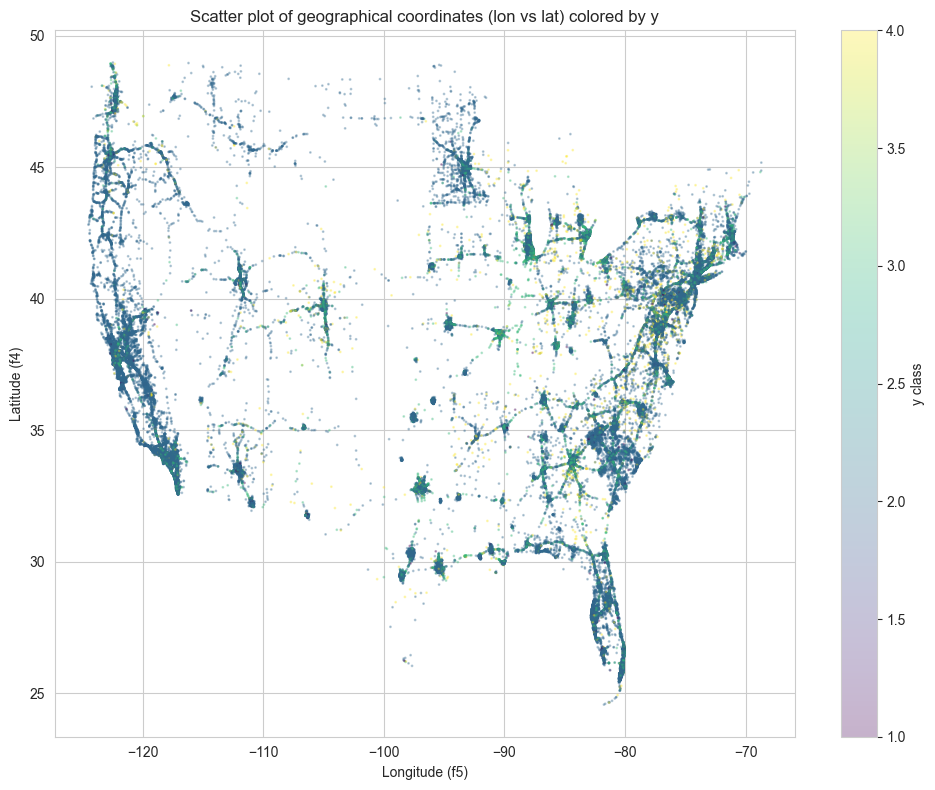

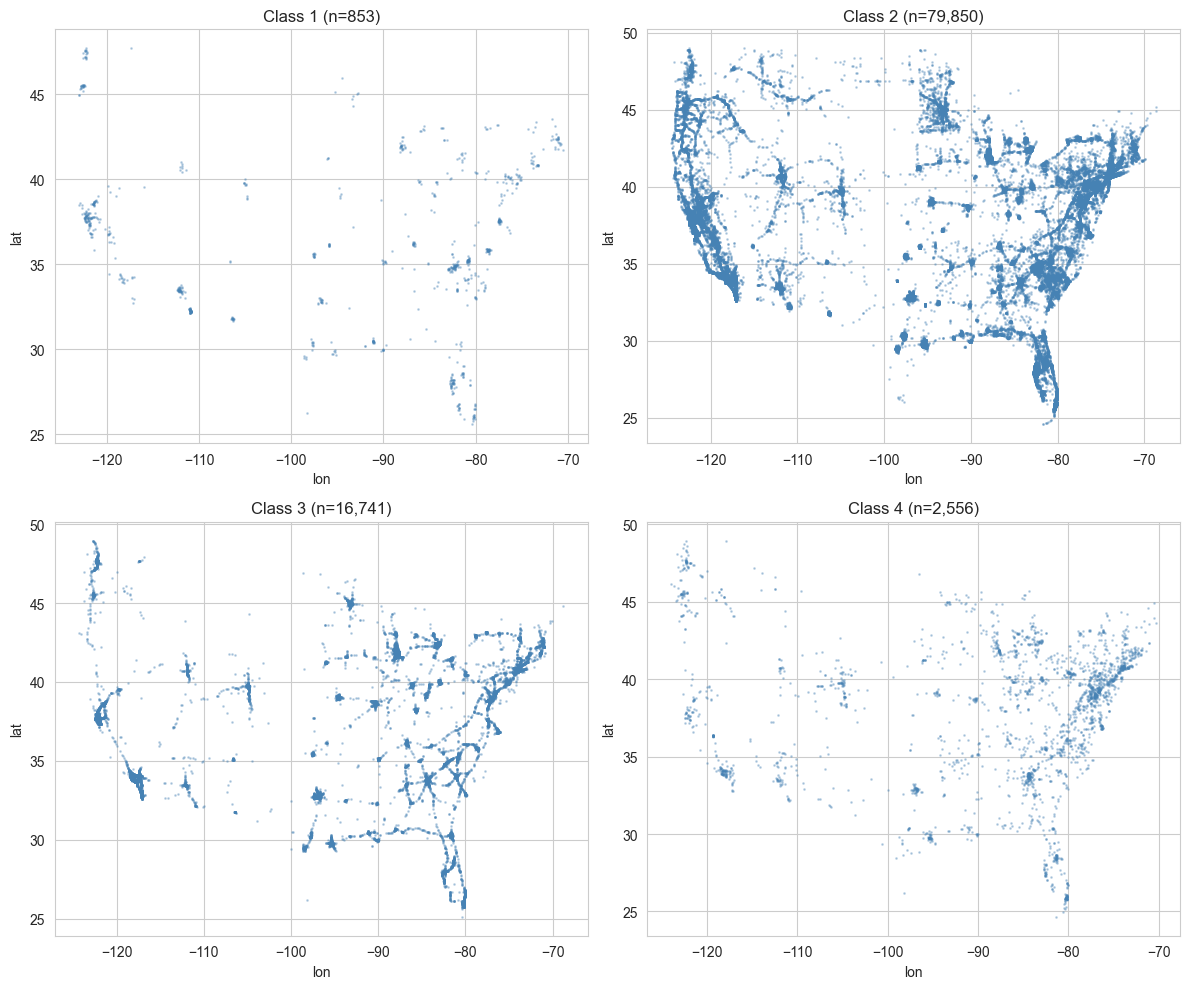

In [14]:
print("\n" + "="*60)
print("Geographical analysis: f4 (lat) vs f5 (lon)")
print("="*60)

if 'f4' in df.columns and 'f5' in df.columns:
    # حذف مقادیر گمشده
    geo_df = df[['f4', 'f5', 'y']].dropna()
    if len(geo_df) > 0:
        plt.figure(figsize=(10,8))
        scatter = plt.scatter(geo_df['f5'], geo_df['f4'], 
                              c=geo_df['y'], cmap='viridis', alpha=0.3, s=1)
        plt.colorbar(scatter, label='y class')
        plt.title('Scatter plot of geographical coordinates (lon vs lat) colored by y')
        plt.xlabel('Longitude (f5)')
        plt.ylabel('Latitude (f4)')
        plt.tight_layout()
        plt.savefig('geo_scatter_by_y.png', dpi=150)
        plt.show()
        
        # همچنین می‌توان توزیع هر کلاس را جداگانه در یک نمودار چندگانه دید
        fig, axes = plt.subplots(2, 2, figsize=(12,10))
        axes = axes.flatten()
        for i, cls in enumerate(sorted(geo_df['y'].unique())):
            if i < 4:
                subset = geo_df[geo_df['y'] == cls]
                axes[i].scatter(subset['f5'], subset['f4'], alpha=0.3, s=1, c='steelblue')
                axes[i].set_title(f'Class {cls} (n={len(subset):,})')
                axes[i].set_xlabel('lon')
                axes[i].set_ylabel('lat')
        plt.tight_layout()
        plt.savefig('geo_by_class.png', dpi=150)
        plt.show()
    else:
        print("No valid coordinates after dropping missing.")

_____________________
 تحلیل زمانی


____________________________________________________________
مرحله 9: تحلیل زمانی (f2, f3, f15)
____________________________________________________________
f2: converted to datetime. Valid entries: 90,388
f3: converted to datetime. Valid entries: 90,388
f15: converted to datetime. Valid entries: 98,491


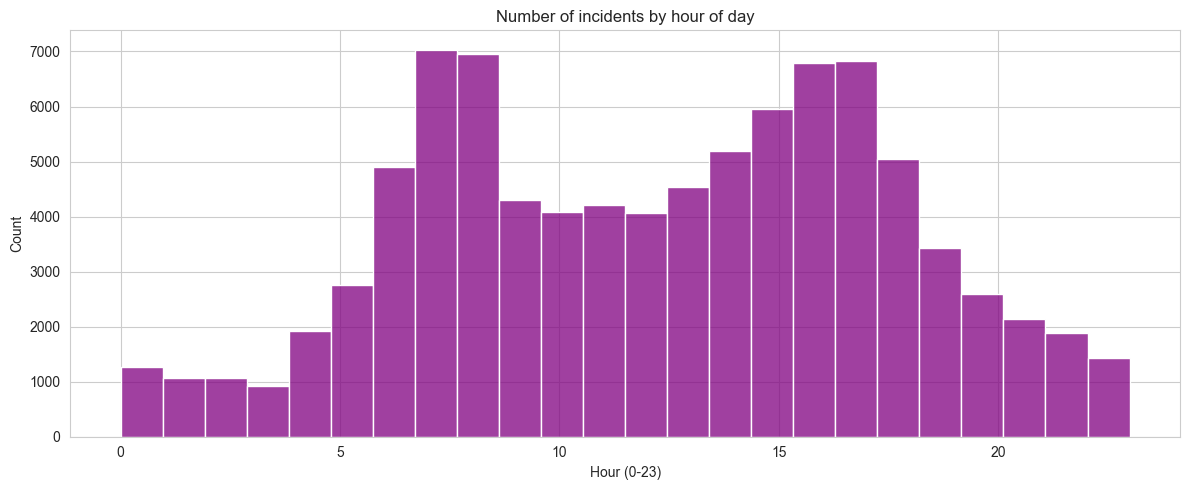

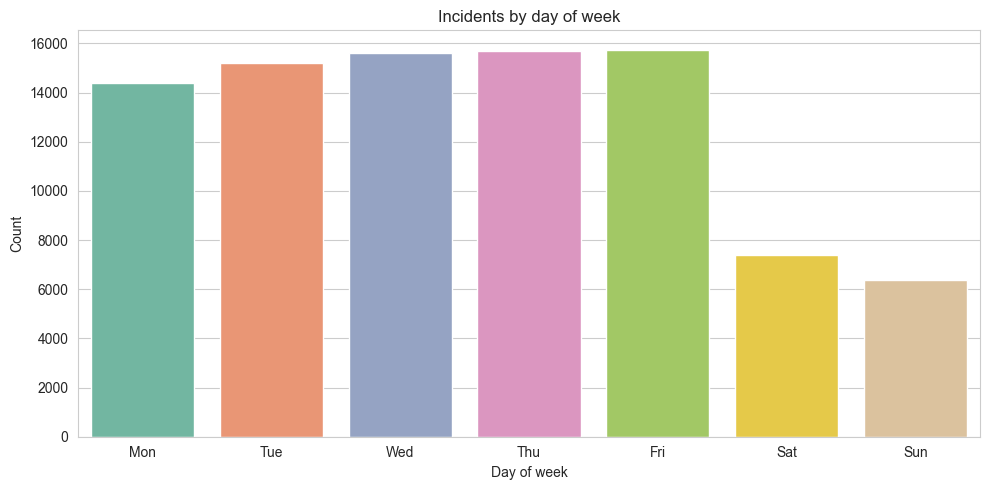

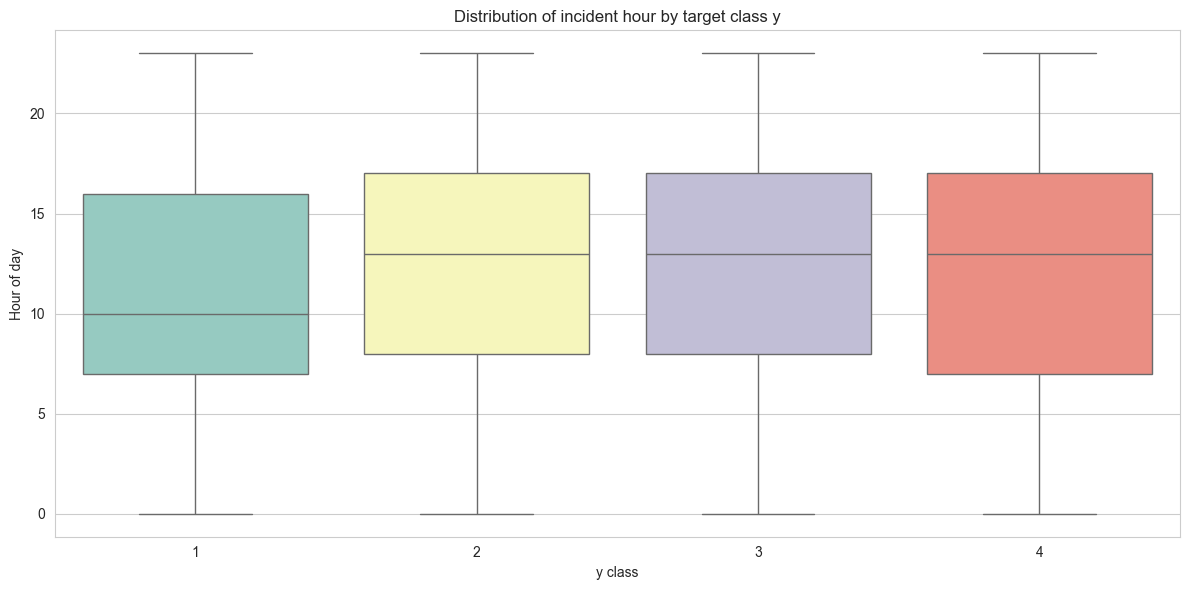


Correlation of temporal features with target y:
is_weekend    0.052446
dayofweek     0.023803
hour          0.015070
month        -0.018149
dtype: float64


In [15]:
print("\n" + "_"*60)
print("مرحله 9: تحلیل زمانی (f2, f3, f15)")
print("_"*60)

time_cols = ['f2', 'f3', 'f15']
for col in time_cols:
    if col in df.columns:
        df[col+'_dt'] = pd.to_datetime(df[col], errors='coerce')
        valid_count = df[col+'_dt'].notna().sum()
        print(f"{col}: converted to datetime. Valid entries: {valid_count:,}")

if 'f2_dt' in df.columns and df['f2_dt'].notna().sum() > 0:
    df['hour'] = df['f2_dt'].dt.hour
    df['dayofweek'] = df['f2_dt'].dt.dayofweek
    df['month'] = df['f2_dt'].dt.month
    df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
    
    plt.figure(figsize=(12,5))
    sns.histplot(df['hour'].dropna(), bins=24, kde=False, color='purple')
    plt.title('Number of incidents by hour of day')
    plt.xlabel('Hour (0-23)')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.savefig('incidents_by_hour.png', dpi=150)
    plt.show()
    
    plt.figure(figsize=(10,5))
    day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    sns.countplot(x='dayofweek', data=df, hue='dayofweek', palette='Set2', legend=False)
    plt.title('Incidents by day of week')
    plt.xlabel('Day of week')
    plt.ylabel('Count')
    plt.xticks(ticks=range(7), labels=day_names)
    plt.tight_layout()
    plt.savefig('incidents_by_dayofweek.png', dpi=150)
    plt.show()
    
    plt.figure(figsize=(12,6))
    sns.boxplot(x='y', y='hour', data=df.dropna(subset=['hour', 'y']), hue='y', palette='Set3', legend=False)
    plt.title('Distribution of incident hour by target class y')
    plt.xlabel('y class')
    plt.ylabel('Hour of day')
    plt.tight_layout()
    plt.savefig('hour_by_y.png', dpi=150)
    plt.show()
    
    temporal_features = ['hour', 'dayofweek', 'month', 'is_weekend']
    temporal_corr = df[temporal_features].corrwith(df['y']).sort_values(ascending=False)
    print("\nCorrelation of temporal features with target y:")
    print(temporal_corr)
else:
    print("No valid datetime data in f2. Skipping temporal analysis.")

__________________________
گزارش کلی EDA

In [16]:
print("\n" + "_"*60)
print("مرحله 10:گزارش کلی از اقدامات صورت گرفته طی فرایند EDA")
print("_"*60)

missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'count_missing': missing_counts, 'percent_missing': missing_percent})
missing_df = missing_df[missing_df['count_missing'] > 0].sort_values(by='percent_missing', ascending=False)

bool_flags = [f'f{i}' for i in range(22, 33) if f'f{i}' in df.columns]

summary = {
    'Total samples': len(df),
    'Total features': len(df.columns),
    'Target classes': sorted(df['y'].dropna().unique()),
    'Class distribution (%)': df['y'].value_counts(normalize=True).mul(100).round(2).to_dict(),
    'Features with >10% missing': missing_df[missing_df['percent_missing'] > 10].index.tolist(),
    'Numerical features analyzed': numerical_cols,
    'Boolean flags (f22-f32)': bool_flags,
    'Outliers in f16 (count)': outlier_report[1]['count'] if len(outlier_report)>1 else 'N/A',
    'Suggested features to remove (high missing/cardinality)': ['f6', 'f8', 'f9', 'f10', 'f11', 'f13', 'f14', 'f32' if 'f32' in df.columns else ''],
    'New temporal features extracted': ['hour', 'dayofweek', 'month', 'is_weekend'] if 'hour' in df.columns else []
}

for k, v in summary.items():
    print(f"{k}: {v}")

with open('EDA_summary.txt', 'w', encoding='utf-8') as f:
    for k, v in summary.items():
        f.write(f"{k}: {v}\n")

print("\n✅ EDA steps 7-10 completed. Summary saved to 'EDA_summary.txt'.")
print("All plots saved as PNG files.")


____________________________________________________________
مرحله 10:گزارش کلی از اقدامات صورت گرفته طی فرایند EDA
____________________________________________________________
Total samples: 100000
Total features: 42
Target classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Class distribution (%): {2: 79.85, 3: 16.74, 4: 2.56, 1: 0.85}
Features with >10% missing: ['f6', 'f16']
Numerical features analyzed: ['f4', 'f5', 'f7', 'f16', 'f17', 'f18', 'f20']
Boolean flags (f22-f32): ['f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31', 'f32']
Outliers in f16 (count): 571
Suggested features to remove (high missing/cardinality): ['f6', 'f8', 'f9', 'f10', 'f11', 'f13', 'f14', 'f32']
New temporal features extracted: ['hour', 'dayofweek', 'month', 'is_weekend']

✅ EDA steps 7-10 completed. Summary saved to 'EDA_summary.txt'.
All plots saved as PNG files.


_______________________

**Pre processing:**

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('group_39_train.csv')
print("کتابخانه‌ها بارگذاری شدند.")

کتابخانه‌ها بارگذاری شدند.


_____________________
مرحله 1 – جداسازی ویژگی‌ها و هدف

In [18]:
print("="*60)
print("مرحله 1: جداسازی X و y")
print("="*60)

X = df.drop('y', axis=1)
y = df['y']
print(f"ابعاد X اولیه: {X.shape}")
print(f"توزیع اولیه y:\n{y.value_counts().sort_index()}")

مرحله 1: جداسازی X و y
ابعاد X اولیه: (100000, 34)
توزیع اولیه y:
y
1      853
2    79850
3    16741
4     2556
Name: count, dtype: int64


____________________
مرحله 2 – حذف ستون‌های بی‌استفاده

In [19]:
print("\n" + "="*60)
print("مرحله 2: حذف ستون‌های ناخواسته")
print("="*60)

cols_to_drop_basic = ['f6', 'f8', 'f9', 'f10', 'f11', 'f12', 'f14', 'f32', 'f33', 'f18']  # f18 اضافه شد
weak_bool_flags = ['f23', 'f24', 'f26', 'f27', 'f30']
all_cols_to_drop = list(set(cols_to_drop_basic + weak_bool_flags))
cols_dropped = [c for c in all_cols_to_drop if c in X.columns]
X = X.drop(columns=cols_dropped)

print(f"ستون‌های حذف شده: {cols_dropped}")
print("دلایل حذف:")
print(" - f6: 44% missing، همبستگی بالا با f5")
print(" - f8, f9, f10, f11, f14: کاردینالیتی بسیار بالا بدون تاثیر واضح بر y")
print(" - f12: مقدار ثابت (همیشه US)")
print(" - f32: همه False یا کاملاً missing")
print(" - f33: تکراری با f34")
print(" - f18: بیش از 99% داده‌ها برابر 10 (مقدار ثابت پس از حذف outliers) - فاقد اطلاعات مفید")
print(" - f23, f24, f26, f27, f30: همبستگی نزدیک به صفر با y")
print(f"ابعاد X پس از حذف: {X.shape}")


مرحله 2: حذف ستون‌های ناخواسته
ستون‌های حذف شده: ['f18', 'f24', 'f23', 'f26', 'f8', 'f11', 'f14', 'f32', 'f27', 'f30', 'f33', 'f12', 'f10', 'f6', 'f9']
دلایل حذف:
 - f6: 44% missing، همبستگی بالا با f5
 - f8, f9, f10, f11, f14: کاردینالیتی بسیار بالا بدون تاثیر واضح بر y
 - f12: مقدار ثابت (همیشه US)
 - f32: همه False یا کاملاً missing
 - f33: تکراری با f34
 - f18: بیش از 99% داده‌ها برابر 10 (مقدار ثابت پس از حذف outliers) - فاقد اطلاعات مفید
 - f23, f24, f26, f27, f30: همبستگی نزدیک به صفر با y
ابعاد X پس از حذف: (100000, 19)


________________
مرحله 3 – مدیریت مقادیر گمشده




In [20]:
print("\n" + "="*60)
print("مرحله 3: مدیریت مقادیر گمشده (Missing Values)")
print("="*60)

# محاسبه درصد missing
missing_percent = X.isnull().sum() / len(X) * 100
print("درصد missing قبل از هرگونه پردازش:")
print(missing_percent[missing_percent > 0])

# 3.1 حذف سطرهایی که در ستون‌های با missing < 5% مقدار گمشده دارند
low_missing_cols = missing_percent[missing_percent < 5].index.tolist()
if low_missing_cols:
    before = len(X)
    X = X.dropna(subset=low_missing_cols)
    after = len(X)
    y = y.loc[X.index]
    print(f"ردیف‌های حذف شده به دلیل missing در ستون‌های {low_missing_cols}: {before - after} ردیف")
    print(f"ابعاد جدید X: {X.shape}")

# شناسایی انواع ستون‌ها (بعد از حذف سطرها)
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
bool_cols = [c for c in X.columns if c.startswith('f') and c[1:].isdigit() and 22 <= int(c[1:]) <= 31]
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
if 'f34' in X.columns and 'f34' not in categorical_cols:
    categorical_cols.append('f34')
categorical_cols = [c for c in categorical_cols if c not in bool_cols]

print(f"\nستون‌های عددی: {numeric_cols}")
print(f"ستون‌های بولی: {bool_cols}")
print(f"ستون‌های categorical (غیربولی): {categorical_cols}")

# 3.2 categorical: جایگزینی با مد (mode)
for col in categorical_cols:
    if X[col].isnull().any():
        mode_val = X[col].mode()[0]
        X[col] = X[col].fillna(mode_val)
        print(f" - {col}: missing با mode '{mode_val}' پر شد.")

# 3.3 boolean: پر کردن تصادفی با حفظ نسبت True/False
for col in bool_cols:
    if X[col].isnull().any():
        true_ratio = X[col].mean()
        false_ratio = 1 - true_ratio
        missing_count = X[col].isnull().sum()
        random_vals = np.random.choice([True, False], size=missing_count, p=[true_ratio, false_ratio])
        X.loc[X[col].isnull(), col] = random_vals
        print(f" - {col}: missing با نسبت True={true_ratio:.3f} به صورت تصادفی پر شد.")

# 3.4 numeric: جایگزینی missing (با روش خاص برای f16 و میانه کلی برای بقیه)
# 3.4.1 ابتدا برای f16: میانه گروهی بر اساس ماه (از f15)
if 'f16' in X.columns and X['f16'].isnull().any():
    # اطمینان از وجود f15 و تبدیل آن به datetime
    if 'f15' in X.columns:
        # تبدیل f15 به datetime (خطاها به NaT تبدیل می‌شوند، اما قبلاً missing f15 حذف شده)
        f15_dt = pd.to_datetime(X['f15'], errors='coerce')
        # استخراج ماه
        month = f15_dt.dt.month
        # محاسبه میانه f16 برای هر ماه
        median_by_month = X.groupby(month)['f16'].transform('median')
        # اگر برای ماهی میانه وجود نداشت (به دلیل نداشتن داده)، از میانه کلی استفاده کن
        overall_median = X['f16'].median()
        median_by_month = median_by_month.fillna(overall_median)
        # پر کردن missingهای f16 با میانه مربوط به ماه
        missing_mask = X['f16'].isnull()
        X.loc[missing_mask, 'f16'] = median_by_month[missing_mask]
        print(f" - f16: missing ها با میانه گروهی بر اساس ماه (از f15) پر شدند.")
    else:
        # fallback: اگر f15 وجود نداشت، از میانه کلی استفاده کن
        median_val = X['f16'].median()
        X['f16'] = X['f16'].fillna(median_val)
        print(f" - f16: missing ها با میانه کلی {median_val:.2f} پر شدند (چون f15 یافت نشد).")

# 3.4.2 سایر ستون‌های عددی: میانه کلی
for col in numeric_cols:
    if col == 'f16':
        continue  # قبلاً انجام شد
    if X[col].isnull().any():
        median_val = X[col].median()
        X[col] = X[col].fillna(median_val)
        print(f" - {col}: missing با میانه {median_val:.2f} پر شد.")

print(f"\nمجموع missing پس از imputation: {X.isnull().sum().sum()}")


مرحله 3: مدیریت مقادیر گمشده (Missing Values)
درصد missing قبل از هرگونه پردازش:
f13     0.102
f15     1.509
f16    25.627
f17     1.727
f19     2.226
f20     7.357
f21     2.173
f34     0.282
dtype: float64
ردیف‌های حذف شده به دلیل missing در ستون‌های ['f1', 'f2', 'f3', 'f4', 'f5', 'f7', 'f13', 'f15', 'f17', 'f19', 'f21', 'f22', 'f25', 'f28', 'f29', 'f31', 'f34']: 3046 ردیف
ابعاد جدید X: (96954, 19)

ستون‌های عددی: ['f4', 'f5', 'f7', 'f16', 'f17', 'f20']
ستون‌های بولی: ['f22', 'f25', 'f28', 'f29', 'f31']
ستون‌های categorical (غیربولی): ['f1', 'f2', 'f3', 'f13', 'f15', 'f19', 'f21', 'f34']
 - f16: missing ها با میانه گروهی بر اساس ماه (از f15) پر شدند.
 - f20: missing با میانه 7.00 پر شد.

مجموع missing پس از imputation: 0


_____________________
مرحله 4 – مدیریت داده‌های پرت

In [21]:
print("\n" + "="*60)
print("مرحله 4: مدیریت داده‌های پرت (Capping)")
print("="*60)

def cap_iqr(series, multiplier=1.5):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - multiplier * IQR
    upper = Q3 + multiplier * IQR
    return series.clip(lower=lower, upper=upper), lower, upper

outlier_cols = ['f7', 'f16', 'f20']
for col in outlier_cols:
    if col in X.columns:
        orig_min, orig_max = X[col].min(), X[col].max()
        capped, low, up = cap_iqr(X[col], multiplier=1.5)
        # محدودیت‌های دستی اضافی
        if col == 'f16':
            capped = capped.clip(upper=120)
        if col == 'f20':
            capped = capped.clip(upper=100)
        X[col] = capped
        print(f"{col}: بازه اصلی [{orig_min:.2f}, {orig_max:.2f}] -> بازه جدید [{X[col].min():.2f}, {X[col].max():.2f}]")


مرحله 4: مدیریت داده‌های پرت (Capping)
f7: بازه اصلی [0.00, 74.37] -> بازه جدید [0.00, 1.15]
f16: بازه اصلی [-46.00, 162.00] -> بازه جدید [-4.00, 120.00]
f20: بازه اصلی [0.00, 129.00] -> بازه جدید [0.00, 18.10]


______________________
مرحله 5 – استخراج ویژگی‌های زمانی و duration

In [22]:
print("\n" + "="*60)
print("مرحله 5: استخراج ویژگی‌های زمانی و duration")
print("="*60)

# 6.1 حذف ردیف‌هایی که f15 نامعتبر دارند (missing کم است)
if 'f15' in X.columns:
    f15_dt = pd.to_datetime(X['f15'], errors='coerce')
    valid_f15 = f15_dt.notna()
    before = len(X)
    X = X[valid_f15].copy()
    y = y[valid_f15].copy()
    f15_dt = f15_dt[valid_f15]
    print(f"ردیف‌های نامعتبر f15 حذف شدند: {before - len(X)} ردیف")
    
    # استخراج ویژگی‌های زمانی
    X['hour'] = f15_dt.dt.hour
    X['dayofweek'] = f15_dt.dt.dayofweek
    X['month'] = f15_dt.dt.month
    X['is_weekend'] = (X['dayofweek'] >= 5).astype(int)
    print("ویژگی‌های hour, dayofweek, month, is_weekend از f15 استخراج شدند.")
else:
    print("هشدار: ستون f15 یافت نشد. ویژگی‌های زمانی ایجاد نخواهند شد.")

# 6.2 محاسبه duration از f2 و f3 (بدون حذف سطر)
if 'f2' in X.columns and 'f3' in X.columns:
    f2_dt = pd.to_datetime(X['f2'], errors='coerce')
    f3_dt = pd.to_datetime(X['f3'], errors='coerce')
    duration_min = (f3_dt - f2_dt).dt.total_seconds() / 60.0
    # تبدیل مقادیر منفی به NaN
    duration_min[duration_min < 0] = np.nan
    X['duration_minutes'] = duration_min
else:
    print("ستون‌های f2 یا f3 موجود نیستند. duration محاسبه نشد.")

# 6.3 پر کردن missingهای duration با میانه
if 'duration_minutes' in X.columns and X['duration_minutes'].isnull().any():
    median_dur = X['duration_minutes'].median()
    X['duration_minutes'] = X['duration_minutes'].fillna(median_dur)
    print(f"missing های duration با میانه {median_dur:.2f} دقیقه پر شدند.")

# 6.4 حذف ستون‌های اصلی زمان
cols_to_remove_time = [c for c in ['f2', 'f3', 'f15'] if c in X.columns]
X = X.drop(columns=cols_to_remove_time)
print(f"ستون‌های زمانی اصلی حذف شدند: {cols_to_remove_time}")


مرحله 5: استخراج ویژگی‌های زمانی و duration
ردیف‌های نامعتبر f15 حذف شدند: 0 ردیف
ویژگی‌های hour, dayofweek, month, is_weekend از f15 استخراج شدند.
missing های duration با میانه 62.50 دقیقه پر شدند.
ستون‌های زمانی اصلی حذف شدند: ['f2', 'f3', 'f15']


_________________
مرحله 6: گروه بندی و multi-hot encoding



In [23]:
print("مرحله 6: گروه‌بندی چنددسته‌ای (Multi-hot) برای f21 و f19")

# ------------------ گروه‌بندی f21 (وضعیت هوا) ------------------
if 'f21' in X.columns:
    # دسته‌ها و کلمات کلیدی
    weather_categories = {
        'Clear': ['clear', 'fair', 'sunny'],
        'Cloudy': ['cloud', 'overcast', 'mostly cloudy', 'partly cloudy'],
        'Rain': ['rain', 'drizzle', 'shower', 'thunderstorm'],
        'Snow': ['snow', 'blizzard', 'flurry', 'ice pellets'],
        'Fog': ['fog', 'mist', 'haze']
    }
    # ایجاد ستون برای هر دسته
    for cat, keywords in weather_categories.items():
        pattern = '|'.join(keywords)
        X[f'Weather_{cat}'] = X['f21'].str.contains(pattern, case=False, na=False).astype(int)
    # دسته Other: مواردی که هیچکدام از دسته‌ها را ندارند
    weather_cols = [f'Weather_{cat}' for cat in weather_categories.keys()]
    X['Weather_Other'] = (X[weather_cols].sum(axis=1) == 0).astype(int)
    # حذف ستون اصلی
    X = X.drop(columns=['f21'])
    print("  - f21: ستون‌های Weather_* (Clear, Cloudy, Rain, Snow, Fog, Other) ایجاد شد.")
else:
    print("  - ستون f21 یافت نشد.")

# ------------------ گروه‌بندی f19 (جهت باد) ------------------
if 'f19' in X.columns:
    # دسته‌ها و کلمات کلیدی (با توجه به مقادیر نمونه)
    wind_categories = {
        'Calm': ['calm', 'CALM'],
        'Variable': ['var', 'variable', 'VRB'],
        'North': ['north', 'nne', 'nnw', 'ne', 'nw', 'n '],
        'South': ['south', 'sse', 'ssw', 'se', 'sw', 's '],
        'East': ['east', 'ene', 'ese', 'e '],
        'West': ['west', 'wnw', 'wsw', 'w ']
    }
    for cat, keywords in wind_categories.items():
        pattern = '|'.join(keywords)
        X[f'Wind_{cat}'] = X['f19'].str.contains(pattern, case=False, na=False).astype(int)
    # حذف ستون اصلی
    X = X.drop(columns=['f19'])
    print("  - f19: ستون‌های Wind_* (Calm, Variable, North, South, East, West) ایجاد شد.")
else:
    print("  - ستون f19 یافت نشد.")


مرحله 6: گروه‌بندی چنددسته‌ای (Multi-hot) برای f21 و f19
  - f21: ستون‌های Weather_* (Clear, Cloudy, Rain, Snow, Fog, Other) ایجاد شد.
  - f19: ستون‌های Wind_* (Calm, Variable, North, South, East, West) ایجاد شد.


____________
مرحله 7 – تبدیل متغیرهای boolian

In [24]:
bool_cols = X.select_dtypes(include=['bool']).columns.tolist()
for col in bool_cols:
    X[col] = X[col].astype(int)
print("Booleans converted to 0/1.")

Booleans converted to 0/1.


_____________
مرحله 8: تبدیل داده های categorical با one-hot encoding

In [25]:
# اکنون فقط f1, f13, f34 نیاز به One-Hot دارند (چون f21 و f19 قبلاً multi-hot شده‌اند)
categorical_cols = ['f1', 'f13', 'f34']
existing_cat = [c for c in categorical_cols if c in X.columns]
if existing_cat:
    X = pd.get_dummies(X, columns=existing_cat, dtype=int)
    print(f"One-Hot encoding برای {existing_cat} انجام شد (خروجی 0/1).")
else:
    print("هیچ ستون categorical برای encoding یافت نشد.")

print(f"ابعاد نهایی X پس از multi-hot و encoding: {X.shape}")

One-Hot encoding برای ['f1', 'f13', 'f34'] انجام شد (خروجی 0/1).
ابعاد نهایی X پس از multi-hot و encoding: (96954, 37)


________________________
مرحله 9 – تقسیم داده


In [26]:
# تقسیم داده به 80% آموزش، 20% آزمایش با استراتیفای برای حفظ نسبت کلاس‌ها
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"ابعاد X_train: {X_train.shape}")
print(f"ابعاد X_test: {X_test.shape}")
print(f"توزیع y_train:\n{y_train.value_counts().sort_index()}")
print(f"توزیع y_test:\n{y_test.value_counts().sort_index()}")

ابعاد X_train: (77563, 37)
ابعاد X_test: (19391, 37)
توزیع y_train:
y
1      665
2    61941
3    13020
4     1937
Name: count, dtype: int64
توزیع y_test:
y
1      166
2    15486
3     3255
4      484
Name: count, dtype: int64


_______
مرحله 10: تغییر نام


In [27]:
# دیکشنری نگاشت نام‌های قدیم به جدید
name_mapping = {
    # ویژگی‌های عددی
    'f4': 'Latitude',
    'f5': 'Longitude',
    'f7': 'Precipitation',
    'f16': 'Temperature_F',
    'f17': 'Pressure_inHg',
    'f20': 'WindSpeed_mph',
    # ویژگی‌های بولی (flag ها)
    'f22': 'Flag_22',
    'f25': 'Flag_25',
    'f28': 'Flag_28',
    'f29': 'Flag_29',
    'f31': 'Flag_31',
    # ویژگی‌های زمانی
    'hour': 'Hour',
    'dayofweek': 'DayOfWeek',
    'month': 'Month',
    'is_weekend': 'IsWeekend',
    'duration_minutes': 'Duration_Min',
    # One-Hot شده‌های f1 (منبع)
    'f1_Source1': 'Source_1',
    'f1_Source2': 'Source_2',
    'f1_Source3': 'Source_3',
    # One-Hot شده‌های f13 (منطقه زمانی)
    'f13_US/Central': 'TZ_Central',
    'f13_US/Eastern': 'TZ_Eastern',
    'f13_US/Mountain': 'TZ_Mountain',
    'f13_US/Pacific': 'TZ_Pacific',
    # Multi-hot برای وضعیت هوا (f21)
    'Weather_Clear': 'Weather_Clear',
    'Weather_Cloudy': 'Weather_Cloudy',
    'Weather_Rain': 'Weather_Rain',
    'Weather_Snow': 'Weather_Snow',
    'Weather_Fog': 'Weather_Fog',
    'Weather_Other': 'Weather_Other',
    # Multi-hot برای جهت باد (f19)
    'Wind_Calm': 'Wind_Calm',
    'Wind_Variable': 'Wind_Variable',
    'Wind_North': 'Wind_North',
    'Wind_South': 'Wind_South',
    'Wind_East': 'Wind_East',
    'Wind_West': 'Wind_West',
    # One-Hot شده‌های f34 (روز/شب)
    'f34_Day': 'Daytime',
    'f34_Night': 'Nighttime'
}

# فقط ستون‌هایی که در X_train وجود دارند را تغییر نام بده
existing_mapping = {old: new for old, new in name_mapping.items() if old in X_train.columns}
X_train.rename(columns=existing_mapping, inplace=True)
X_test.rename(columns=existing_mapping, inplace=True)

print("نام ستون‌ها با موفقیت تغییر کرد.")
print("ستون‌های جدید:", list(X_train.columns)[:10], "...")

نام ستون‌ها با موفقیت تغییر کرد.
ستون‌های جدید: ['Latitude', 'Longitude', 'Precipitation', 'Temperature_F', 'Pressure_inHg', 'WindSpeed_mph', 'Flag_22', 'Flag_25', 'Flag_28', 'Flag_29'] ...


____________________
**Feature Selection:**

In [32]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.ensemble import RandomForestClassifier

_____________
1. Mutual Information (SelectKBest)

In [33]:
selector_mi = SelectKBest(mutual_info_classif, k=25)
X_train_mi = selector_mi.fit_transform(X_train, y_train)
mi_scores = pd.Series(selector_mi.scores_, index=X_train.columns)
mi_rank = mi_scores.rank(ascending=False).astype(int)

_______________
2. Random Forest Feature Importance

In [34]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_imp = pd.Series(rf.feature_importances_, index=X_train.columns)
rf_rank = rf_imp.rank(ascending=False).astype(int)


_________________
3. RFE with Random Forest (Recursive Feature Elimination)

In [36]:
# برای سرعت بیشتر می‌توانیم n_estimators=50 استفاده کنیم
rfe = RFE(estimator=RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1), 
          n_features_to_select=23, step=2)
X_train_rfe = rfe.fit_transform(X_train, y_train)
rfe_rank = pd.Series(rfe.ranking_, index=X_train.columns)   # 1 بهترین، اعداد بالاتر بدتر


_________________
ساخت جدول مقایسه و میانگین رتبه

In [37]:
comparison = pd.DataFrame({
    'Mutual_Info_Score': mi_scores,
    'Mutual_Info_Rank': mi_rank,
    'RF_Importance': rf_imp,
    'RF_Rank': rf_rank,
    'RFE_Rank': rfe_rank
})

# میانگین رتبه (هرچه کمتر بهتر)
comparison['Avg_Rank'] = (comparison['Mutual_Info_Rank'] + comparison['RF_Rank'] + comparison['RFE_Rank']) / 3

In [38]:
# انتخاب 23 ویژگی بر اساس میانگین رتبه (کمترین مقدار)
selected_features = comparison.sort_values('Avg_Rank').head(23).index.tolist()

print("=== نتایج Feature Selection ===")
print(comparison.sort_values('Avg_Rank').head(37))
print(f"\n✅ {len(selected_features)} ویژگی انتخاب شدند:")
print(selected_features)

=== نتایج Feature Selection ===
                Mutual_Info_Score  Mutual_Info_Rank  RF_Importance  RF_Rank  \
Duration_Min             0.109732                 1       0.118773        1   
Longitude                0.088530                 3       0.102824        3   
Latitude                 0.070496                 6       0.102825        2   
Source_1                 0.101999                 2       0.052031        9   
Precipitation            0.083509                 5       0.055672        7   
Pressure_inHg            0.011518                 9       0.081022        4   
Temperature_F            0.020798                 8       0.065115        5   
WindSpeed_mph            0.025741                 7       0.053537        8   
Source_2                 0.085829                 4       0.040280       12   
Month                    0.010228                11       0.044331       10   
Flag_31                  0.007609                13       0.034674       13   
Hour                

In [39]:
#اضافه کردن f1_source3و f34_night برای تفسیرپذیری
for feature in ['Source_3', 'Nighttime']:
    if feature in X_train.columns:
        if feature not in selected_features:
            selected_features.append(feature)

In [40]:
# اعمال بر روی X_train و X_test
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print(f"\nابعاد جدید X_train: {X_train_selected.shape}")
print(f"ابعاد جدید X_test: {X_test_selected.shape}")


ابعاد جدید X_train: (77563, 24)
ابعاد جدید X_test: (19391, 24)


_________________
نرمال سازی داده های عددی پیوسته

In [41]:

from sklearn.preprocessing import StandardScaler

In [42]:
continuous_features = ['Latitude','Longitude','Precipitation','Temperature_F','Pressure_inHg','WindSpeed_mph','Duration_Min']

# فقط ویژگی‌هایی که در داده وجود دارند و در selected_features هستند
to_scale = [col for col in continuous_features if col in X_train.columns]

if to_scale:
    scaler = StandardScaler()
    X_train[to_scale] = scaler.fit_transform(X_train[to_scale])
    X_test[to_scale] = scaler.transform(X_test[to_scale])
    print("نرمال‌سازی (StandardScaler) روی ویژگی‌های زیر انجام شد:", to_scale)
else:
    print("هیچ ویژگی پیوسته‌ای برای نرمال‌سازی یافت نشد.")

نرمال‌سازی (StandardScaler) روی ویژگی‌های زیر انجام شد: ['Latitude', 'Longitude', 'Precipitation', 'Temperature_F', 'Pressure_inHg', 'WindSpeed_mph', 'Duration_Min']


In [43]:
X_train.to_csv('view.csv', index='False')